In [28]:
############################################
import timeit
import sys
import os
import glob
import warnings
import matplotlib.pyplot as plt
# from pkg.PyQSOFit.PyQSOFit import QSOFit
import numpy as np
import matplotlib

from astropy.io import fits
from astropy.io import ascii
from astropy.table import Table
from astropy import units as u
from astropy.cosmology import WMAP9 as cosmo

from tqdm import tnrange, tqdm_notebook
import pandas as pd

from itertools import product

##########################################
%matplotlib inline
warnings.filterwarnings("ignore")
##########################################

In [29]:
cosmo.age(5)

<Quantity 1.19002429 Gyr>

# Func 

In [30]:
def magToLuminosity(mag, mag_err, redshift, ins, band, log_scale=True):
    
    if ins == 'ZTF':
        if band == 'g':
            lambda_eff = 4722.74 * 10**(-10)
            F_nu0 = 3963.97
        if band == 'r':
            lambda_eff = 6339.61 * 10**(-10)
            F_nu0 = 3042.00
        if band == 'i':
            lambda_eff = 7886.13 * 10**(-10)
            F_nu0 = 2426.09
    if ins == 'WISE':
        if band == 'W1':
            lambda_eff = 33526.00 * 10**(-10)
            F_nu0 = 309.540
        if band == 'W2':
            lambda_eff = 46028.00 * 10**(-10)
            F_nu0 = 171.787
            
    c = 299792458  
    nu = c/lambda_eff 
    dist = cosmo.luminosity_distance(redshift).cgs.value
    
    mag = np.array(mag)
    mag_err = np.array(mag_err)
        
    F_nu = F_nu0 * 10**(-mag/2.5)
    F_nu_err = np.sqrt((np.log(10)*F_nu*mag_err)**2)
    
    nuL = F_nu * 10**(-23) * nu * 4*np.pi*dist**2
    nuL_err = F_nu_err * 10**(-23) * nu * 4*np.pi*dist**2
    
    log_nuL = np.log10(nuL)
    log_nuL_err = np.sqrt((nuL_err/nuL)**2)/np.log(10)

    
    if log_scale:
        return np.array(log_nuL), np.array(log_nuL_err)
    else:
        return np.array(nuL), np.array(nuL_err)

In [31]:
def mag2L(mag, mag_err, dist, ins, band, logscale = True):
    
    if ins == 'ZTF':
        if band == 'g':
            lambda_eff = 4722.74 * 10**(-10)
            F_nu0 = 3963.97
        if band == 'r':
            lambda_eff = 6339.61 * 10**(-10)
            F_nu0 = 3042.00
        if band == 'i':
            lambda_eff = 7886.13 * 10**(-10)
            F_nu0 = 2426.09
    if ins == 'WISE':
        if band == 'W1':
            lambda_eff = 33526.00 * 10**(-10)
            F_nu0 = 309.540
        if band == 'W2':
            lambda_eff = 46028.00 * 10**(-10)
            F_nu0 = 171.787
            
    c = 299792458  
    nu = c/lambda_eff 
    
    mag = np.array(mag)
    mag_err = np.array(mag_err)
        
    F_nu = F_nu0 * 10**(-mag/2.5)
    F_nu_err = np.sqrt((np.log(10)*F_nu*mag_err)**2)
    
    nuL = F_nu * 10**(-23) * nu * 4*np.pi*dist**2
    nuL_err = F_nu_err * 10**(-23) * nu * 4*np.pi*dist**2
    
    log_nuL = np.log10(nuL)
    log_nuL_err = np.sqrt((nuL_err/nuL)**2)/np.log(10)

    
    if logscale:
        return np.array(log_nuL), np.array(log_nuL_err)
    else:
        return np.array(nu_L), np.array(nu_L_err)

In [32]:
def reBin(mjd, mag, binSize):
    t_list_bin = np.unique(mjd//binSize)
    t_norm = np.array(mjd//binSize)
    
    t_bin = []
    mag_bin = []
    mag_err_bin = []
    for i in np.arange(len(t_list_bin)):
        ii = t_list_bin[i]
        t_list = []
        mag_list = []
        for j in np.arange(len(t_norm)):
            jj = t_norm[j]
            if jj == ii:
                t_list.append(mjd[j])
                mag_list.append(mag[j])
            else:
                t_list.append(np.nan)
                mag_list.append(np.nan)
        t_bin.append(np.nanmedian(np.array(t_list)))
        mag_bin.append(np.nanmedian(np.array(mag_list)))
        mag_err_bin.append(np.nanstd(np.array(mag_list)))

    t_bin = np.array(t_bin)
    mag_bin = np.array(mag_bin)
    mag_err_bin = np.array(mag_err_bin)
    
    return t_bin, mag_bin, mag_err_bin

In [33]:
def lcNeoWise(lc_file,binSize = 100):
    
    wise_df = pd.read_csv(lc_file)
    wise_sort_df = wise_df.sort_values(by="mjd", ascending=True)
    tMjd = np.array(wise_sort_df["mjd"])
    magW1 = np.array(wise_sort_df["w1mpro"])
    magW1Err = np.array(wise_sort_df["w1sigmpro"])
    magW2 = np.array(wise_sort_df["w2mpro"])
    magW2Err = np.array(wise_sort_df["w2sigmpro"])
    
    tBin, magW1Bin, magW1ErrBin = reBin(tMjd, magW1, binSize)
    tBin, magW2Bin, magW2ErrBin = reBin(tMjd, magW2, binSize)
    
    return tBin, magW1Bin, magW1ErrBin, magW2Bin, magW2ErrBin

In [34]:
def lcZTF(lc_file, ifBin=False, binSize=10):
    
    lc = fits.open(lc_file)
    tMjd = lc[1].data["mjd"]
    mag = lc[1].data["mag"]
    magErr = lc[1].data["magerr"]
    
    if ifBin:
        tBin, magBin, magErrBin = reBin(tMjd, mag, binSize)
        return tBin, magBin, magErrBin
    else:
        return tMjd, mag, magErr

In [35]:
def lcFile(target_name, target_z, lc_data_path, neoWISE_path, ZTF_path, 
           binSizeWISE=100, ifBin=False, binSizeZTF=10, log_scale=True, save_data=False, ):
    ######### load data ########
    
    ####### WISE #########
    neoWISE_lc_file = glob.glob(dataPath+neoWISE_path+"*"+target_name+"*")[0]
    mjd_WISE, mag_W1, mag_err_W1, mag_W2, mag_err_W2 = lcNeoWise(neoWISE_lc_file, binSize = binSizeWISE)
    nuL_W1, nuL_err_W1 = magToLuminosity(mag_W1, mag_err_W1, target_z, ins="WISE", band="W1", log_scale=log_scale)
    nuL_W2, nuL_err_W2 = magToLuminosity(mag_W2, mag_err_W2, target_z, ins="WISE", band="W2", log_scale=log_scale)
    band_W1 = list(len(mjd_WISE)*["W1"])
    band_W2 = list(len(mjd_WISE)*["W2"])
    
    ###### ZTF  ##########
    ZTF_band_list = ["ZTFg","ZTFr","ZTFi"]
    file_list = glob.glob(dataPath+ZTF_path+"*"+target_name+"*")
    band = [i for i,j in product(ZTF_band_list,file_list) if i in j]
    
    if "ZTFg" in band:
        ZTFg_lc_file = [i for i in file_list if "ZTFg" in i][0]
        mjd_ZTFg, mag_ZTFg, mag_err_ZTFg = lcZTF(ZTFg_lc_file, ifBin=ifBin, binSize=binSizeZTF)
        nuL_g, nuL_err_g = magToLuminosity(mag_ZTFg, mag_err_ZTFg, target_z, ins="ZTF", band="g", log_scale=log_scale)
        band_g = list(len(mjd_ZTFg)*["g"])
    else:
        mjd_ZTFg, mag_ZTFg, mag_err_ZTFg, nuL_g, nuL_err_g, band_g = [],[],[],[],[],[]
        
    if "ZTFr" in band:
        ZTFr_lc_file = [i for i in file_list if "ZTFr" in i][0]
        mjd_ZTFr, mag_ZTFr, mag_err_ZTFr = lcZTF(ZTFr_lc_file, ifBin=ifBin, binSize=binSizeZTF)
        nuL_r, nuL_err_r = magToLuminosity(mag_ZTFr, mag_err_ZTFr, target_z, ins="ZTF", band="r", log_scale=log_scale)
        band_r = list(len(mjd_ZTFr)*["r"])
    else:
        mjd_ZTFr, mag_ZTFr, mag_err_ZTFr, nuL_r, nuL_err_r, band_r = [],[],[],[],[],[]
        
    if "ZTFi" in band:
        ZTFi_lc_file = [i for i in file_list if "ZTFi" in i][0]
        mjd_ZTFi, mag_ZTFi, mag_err_ZTFi = lcZTF(ZTFi_lc_file, ifBin=ifBin, binSize=binSizeZTF)
        nuL_i, nuL_err_i = magToLuminosity(mag_ZTFi, mag_err_ZTFi, target_z, ins="ZTF", band="i", log_scale=log_scale)
        band_i = list(len(mjd_ZTFi)*["i"])
    else:
        mjd_ZTFi, mag_ZTFi, mag_err_ZTFi, nuL_i, nuL_err_i, band_i = [],[],[],[],[],[]
      

    data = Table()
    data["MJD"] = list(mjd_WISE)+list(mjd_WISE)+list(mjd_ZTFg)+list(mjd_ZTFr)+list(mjd_ZTFi)
    data["mag"] = list(mag_W1)+list(mag_W2)+list(mag_ZTFg)+list(mag_ZTFr)+list(mag_ZTFi)
    data["magerr"] = list(mag_err_W1)+list(mag_err_W2)+list(mag_err_ZTFg)+list(mag_err_ZTFr)+list(mag_err_ZTFi)
    data["log_nuL"] = list(nuL_W1)+list(nuL_W2)+list(nuL_g)+list(nuL_r)+list(nuL_i)
    data["log_nuLerr"] = list(nuL_err_W1)+list(nuL_err_W2)+list(nuL_err_g)+list(nuL_err_r)+list(nuL_err_i)
    data["band"] = band_W1+band_W2+band_g+band_r+band_i
    
    if save_data:
        ascii.write(data,lc_data_path+target_name+"_lcData.dat",overwrite=True)
        print("Save data completed")
        
    return

In [36]:
def lcShow(lc_data_file, target_name,  plot_flux=False, ):
    
    ######### load data #########
    lc_df = ascii.read(lc_data_file)
    mjd_all = lc_df["MJD"]
    mag_all = lc_df["mag"]
    mag_err_all = lc_df["magerr"]
    nuL_all = lc_df["log_nuL"]
    nuL_err_all = lc_df["log_nuLerr"]
    band_all = lc_df["band"]
    band_list = np.unique(np.array(band_all))
    
    W1_mask = band_all == "W1"
    W2_mask = band_all == "W2"
    mjd_WISE, mag_W1, mag_err_W1, mag_W2, mag_err_W2 = mjd_all[W1_mask], mag_all[W1_mask], mag_err_all[W1_mask], \
                                                                         mag_all[W2_mask], mag_err_all[W2_mask]
    nuL_W1, nuL_err_W1, nuL_W2, nuL_err_W2 = nuL_all[W1_mask], nuL_err_all[W1_mask], nuL_all[W2_mask], nuL_err_all[W2_mask]
    
    gband = True if 'g' in band_list else False
    rband = True if 'r' in band_list else False
    iband = True if 'i' in band_list else False
    
    if gband:
        g_mask  = band_all == "g"
        mjd_ZTFg, mag_ZTFg, mag_err_ZTFg, nuL_g, nuL_err_g = mjd_all[g_mask], mag_all[g_mask], mag_err_all[g_mask], \
                                                                              nuL_all[g_mask], nuL_err_all[g_mask]
    if rband:
        r_mask  = band_all == "r"
        mjd_ZTFr, mag_ZTFr, mag_err_ZTFr, nuL_r, nuL_err_r = mjd_all[r_mask], mag_all[r_mask], mag_err_all[r_mask], \
                                                                              nuL_all[r_mask], nuL_err_all[r_mask]
    if iband:
        i_mask  = band_all == "i"
        mjd_ZTFi, mag_ZTFi, mag_err_ZTFi, nuL_i, nuL_err_i = mjd_all[i_mask], mag_all[i_mask], mag_err_all[i_mask], \
                                                                              nuL_all[i_mask], nuL_err_all[i_mask]
    ###### PLOT #########
    
    fig = plt.figure(figsize = (6,4), dpi = 200)
    ax  = plt.subplot(111)
    ax.tick_params(axis='both', which='major', labelsize=10)
    ax.tick_params(axis='both', which='minor', labelsize=10)
    ax.set_xlabel(r"${\rm  MJD\ [days]}$", fontsize=15)
    ax.set_title(target_name, fontsize=15)

    
    if plot_flux:
        ax.set_ylabel(r"${{\rm log}\ \nu L_{\nu}\ [\rm ergs^{-1}] }$", fontsize=15)
#         ax.set_ylim(nuL_r.max()+0.5, nuL_r.min()-0.5)
        ax.errorbar(mjd_WISE, nuL_W1, yerr = nuL_err_W1, linestyle = 'None', color = "C0", marker = 'o',
                    ms=3, elinewidth=1.1, alpha = 0.6)
        ax.scatter(mjd_WISE, nuL_W1, color = 'C0', s = 4, alpha = 0.5, label = "W1 [NEOWISE]")

        ax.errorbar(mjd_WISE, nuL_W2, yerr = nuL_err_W2, linestyle = 'None', color = "C1", marker = 'o',
                    ms=3, elinewidth=1.1, alpha = 0.6)
        ax.scatter(mjd_WISE, nuL_W2, color = 'C1', s = 4, alpha = 0.5, label = "W2 [NEOWISE]")
        
        if gband:
            ax.errorbar(mjd_ZTFg, nuL_g, yerr = nuL_err_g, linestyle = 'None', color = "C2", marker = 'o',
                    ms=3, elinewidth=1.1, alpha = 0.6)
            ax.scatter(mjd_ZTFg, nuL_g, color = 'C2', s = 4, alpha = 0.5, label = "g [ZTF]")
            
        if rband:
            ax.errorbar(mjd_ZTFr, nuL_r, yerr = nuL_err_r, linestyle = 'None', color = "C3", marker = 'o',
                    ms=3, elinewidth=1.1, alpha = 0.6)
            ax.scatter(mjd_ZTFr, nuL_r, color = 'C3', s = 4, alpha = 0.5, label = "r [ZTF]")
            
        if iband:
            ax.errorbar(mjd_ZTFi, nuL_i, yerr = nuL_err_i, linestyle = 'None', color = "C4", marker = 'o',
                    ms=3, elinewidth=1.1, alpha = 0.6)
            ax.scatter(mjd_ZTFi, nuL_i, color = 'C4', s = 4, alpha = 0.5, label = "i [ZTF]")
            
        plt.legend(fontsize = 8.0,markerscale = 1.2)

    else:
        ax.set_ylabel(r"${\rm magnitude }$", fontsize=15)
        ax.set_ylim(mag_ZTFr.max()+1, mag_W2.min()+3.339-0.5)
        ax.errorbar(mjd_WISE, mag_W1+2.699, yerr = mag_err_W1, linestyle = 'None', color = "C0", marker = 'o',
                    ms=3, elinewidth=1.1, alpha = 0.6)
        ax.scatter(mjd_WISE, mag_W1+2.699, color = 'C0', s = 4, alpha = 0.5, label = "W1+2.699 [NEOWISE]")

        ax.errorbar(mjd_WISE, mag_W2+3.339, yerr = mag_err_W2, linestyle = 'None', color = "C1", marker = 'o',
                    ms=3, elinewidth=1.1, alpha = 0.6)
        ax.scatter(mjd_WISE, mag_W2+3.339, color = 'C1', s = 4, alpha = 0.5, label = "W2+3.339 [NEOWISE]")

        if gband:
            ax.errorbar(mjd_ZTFg, mag_ZTFg, yerr = mag_err_ZTFg, linestyle = 'None', color = "C2", marker = 'o',
                    ms=3, elinewidth=1.1, alpha = 0.6)
            ax.scatter(mjd_ZTFg, mag_ZTFg, color = 'C2', s = 4, alpha = 0.5, label = "g [ZTF]")
            
        if rband:
            ax.errorbar(mjd_ZTFr, mag_ZTFr, yerr = mag_err_ZTFr, linestyle = 'None', color = "C3", marker = 'o',
                    ms=3, elinewidth=1.1, alpha = 0.6)
            ax.scatter(mjd_ZTFr, mag_ZTFr, color = 'C3', s = 4, alpha = 0.5, label = "r [ZTF]")
            
        if iband:
            ax.errorbar(mjd_ZTFi, mag_ZTFi, yerr = mag_err_ZTFi, linestyle = 'None', color = "C4", marker = 'o',
                    ms=3, elinewidth=1.1, alpha = 0.6)
            ax.scatter(mjd_ZTFi, mag_ZTFi, color = 'C4', s = 4, alpha = 0.5, label = "i [ZTF]")
            
        plt.legend(fontsize = 8.0,markerscale = 1.2)
        
    return    

# light curve check

In [37]:
dataPath = "data/lc/"
neoWISE_path = "neoWISE/"
ZTF_path = "ZTF/"
tar_info = ascii.read("data/target_info.dat")
tar_name = list(tar_info["Object"])
tar_z = list(tar_info["z"])

In [38]:
for i in tnrange(len(tar_name)):
    obj_name = tar_name[i]
    obj_z = tar_z[i]
    lcFile(target_name=obj_name, target_z=obj_z, lc_data_path=dataPath, neoWISE_path=neoWISE_path, ZTF_path=ZTF_path, 
           binSizeWISE=100, ifBin=False, binSizeZTF=10, log_scale=True, save_data=True)

  0%|          | 0/11 [00:00<?, ?it/s]

Save data completed
Save data completed
Save data completed
Save data completed
Save data completed
Save data completed
Save data completed
Save data completed
Save data completed
Save data completed
Save data completed


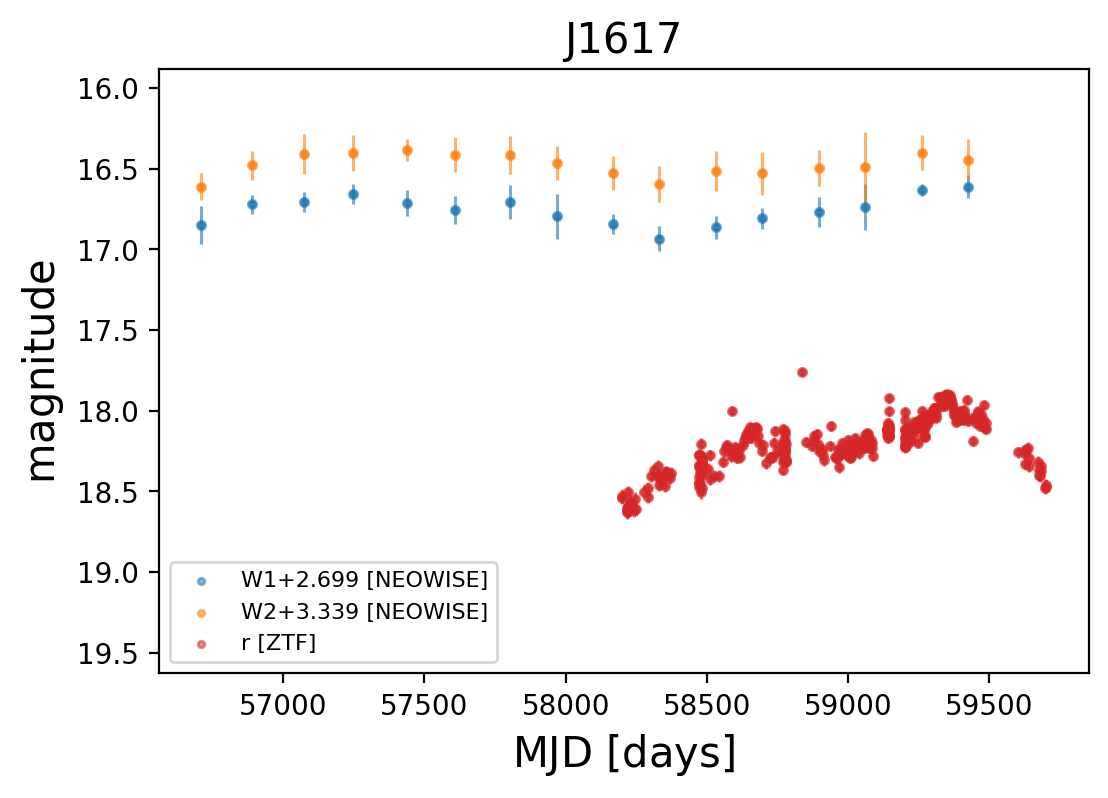

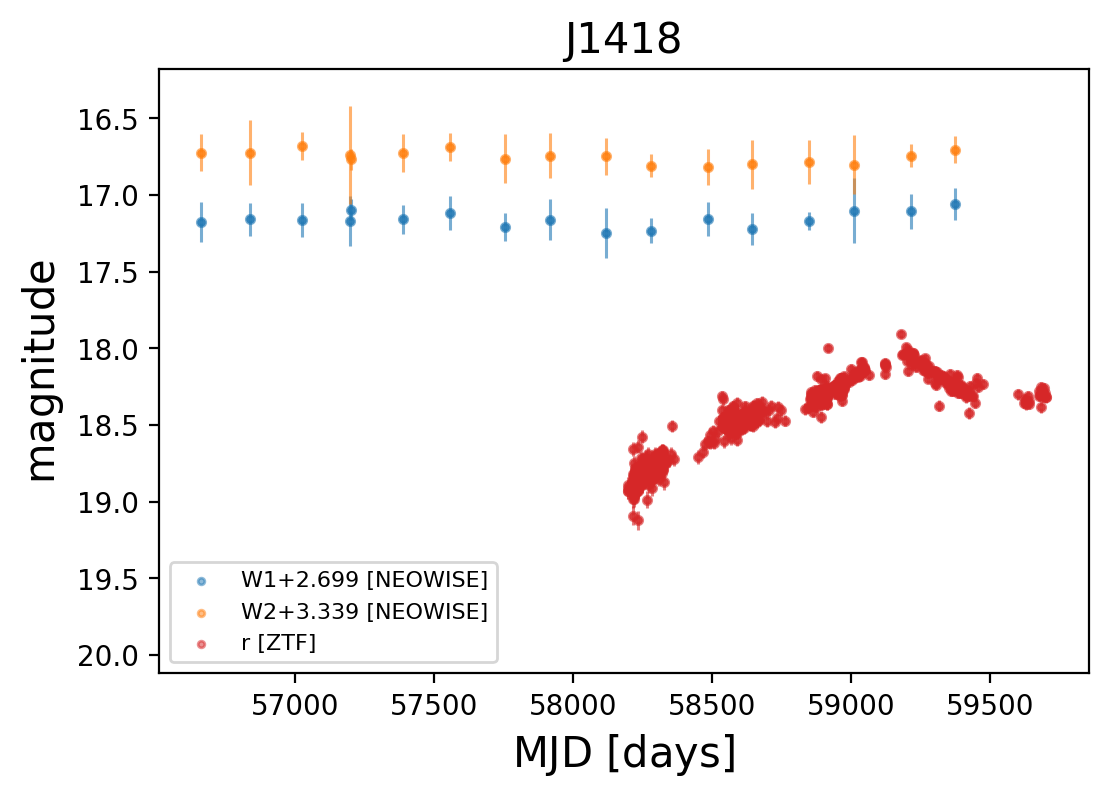

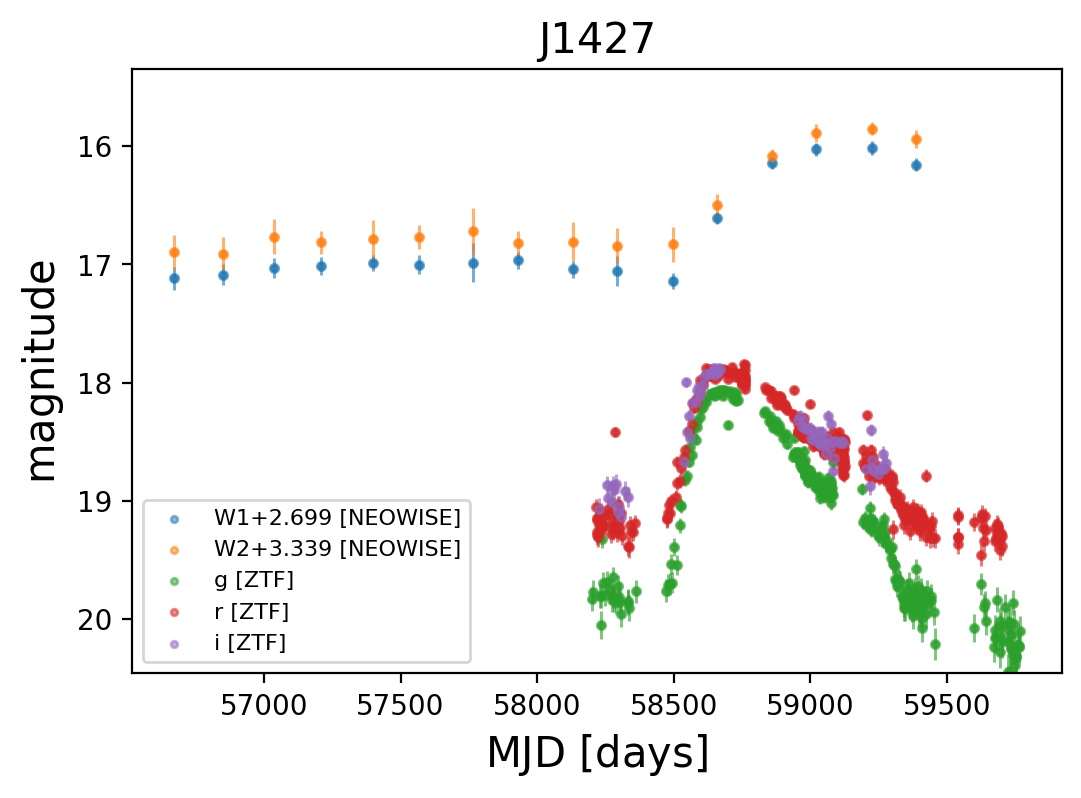

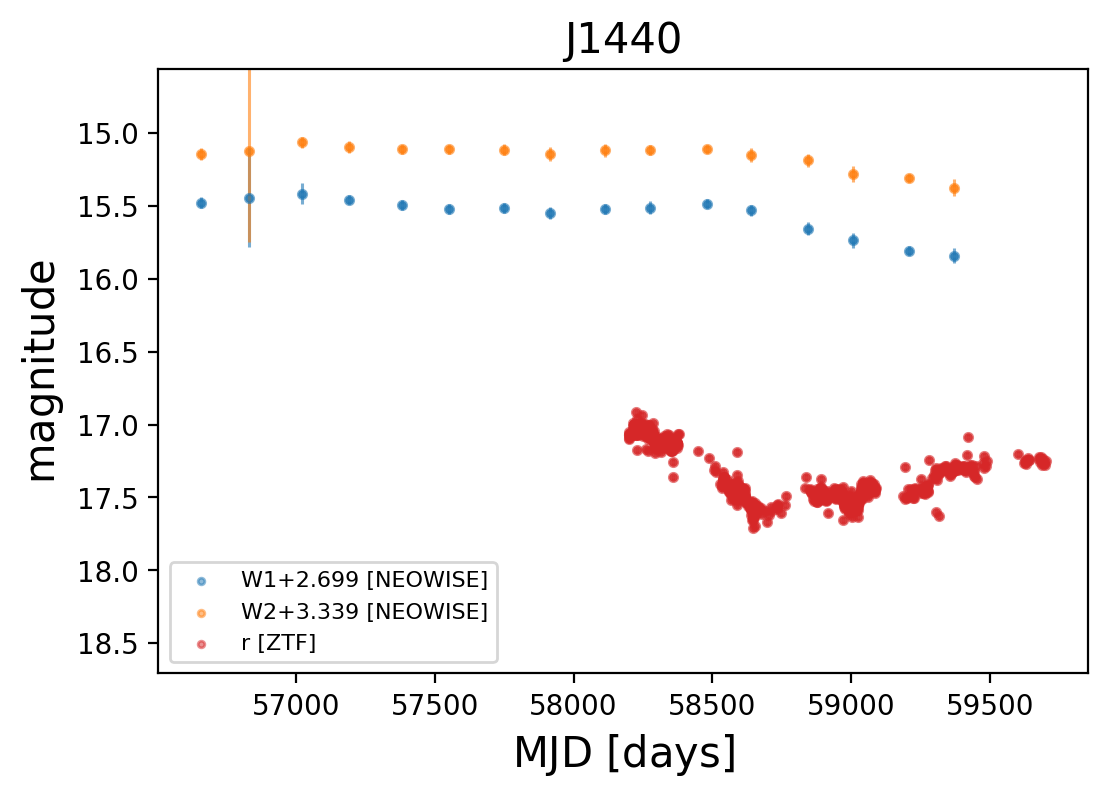

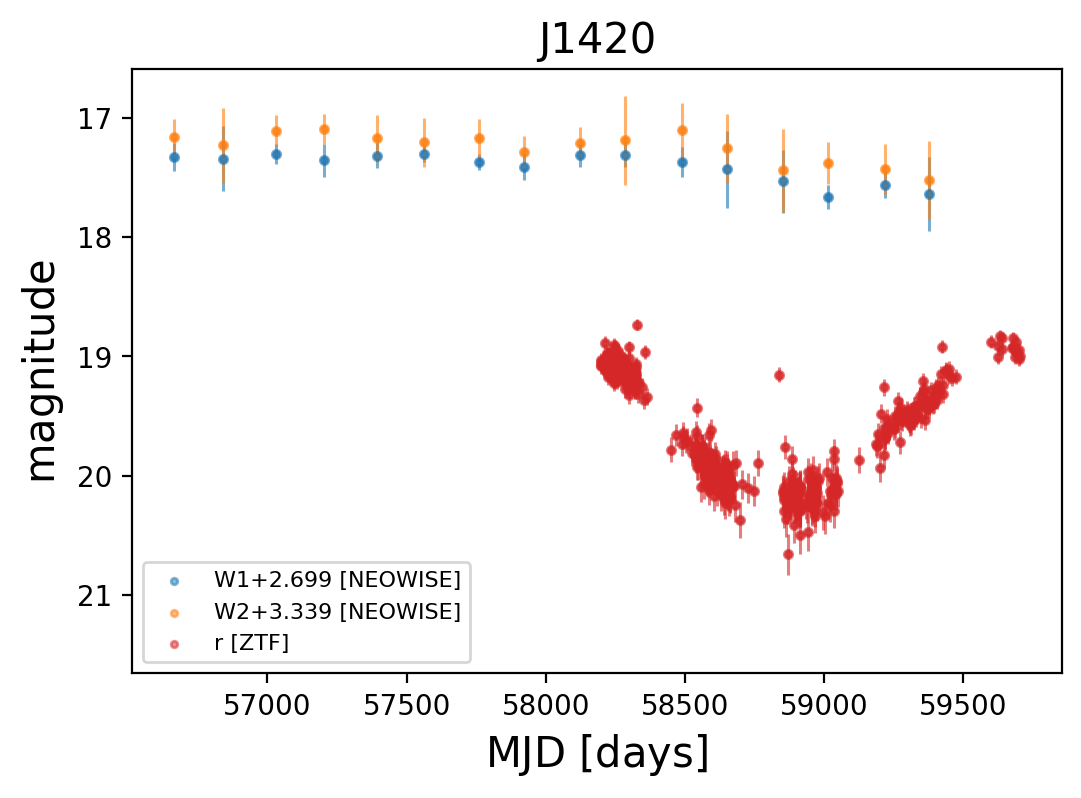

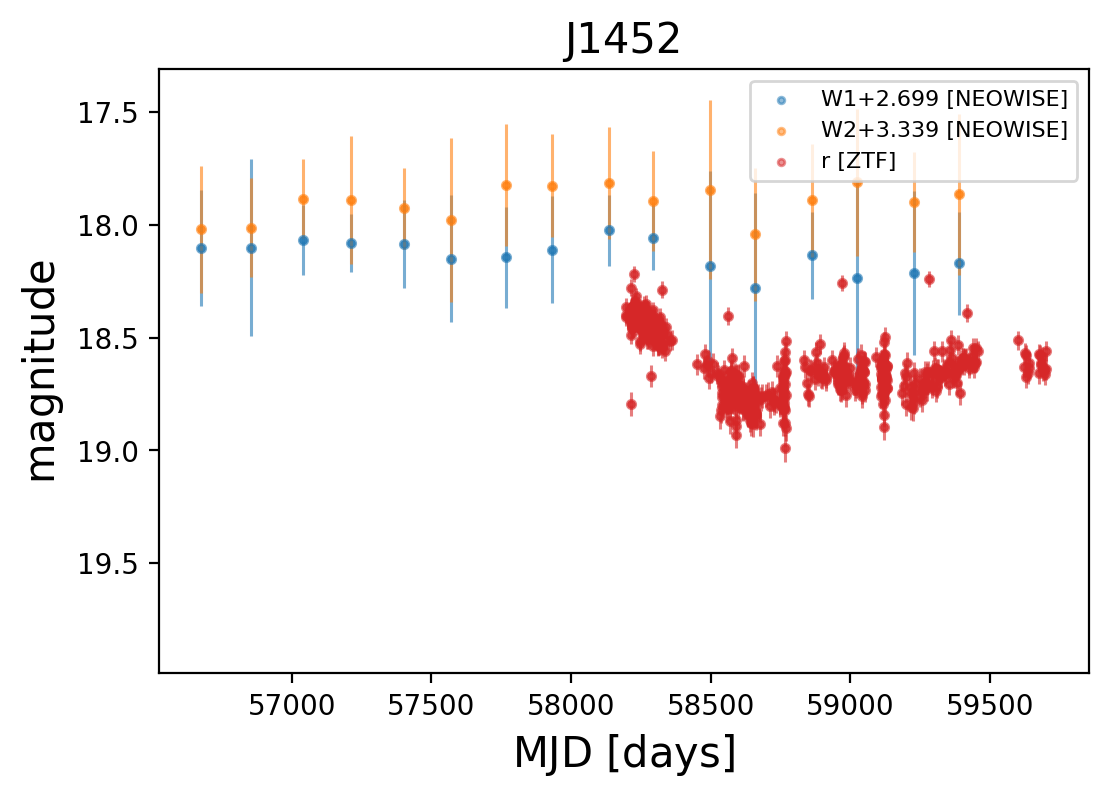

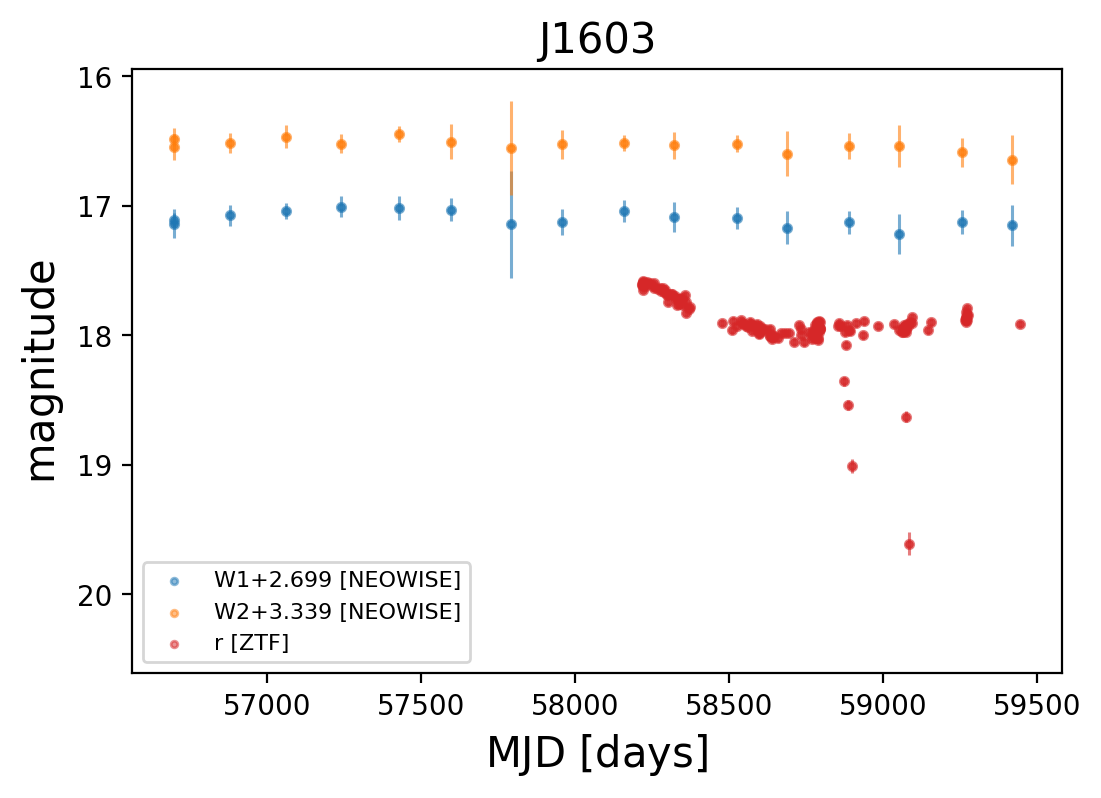

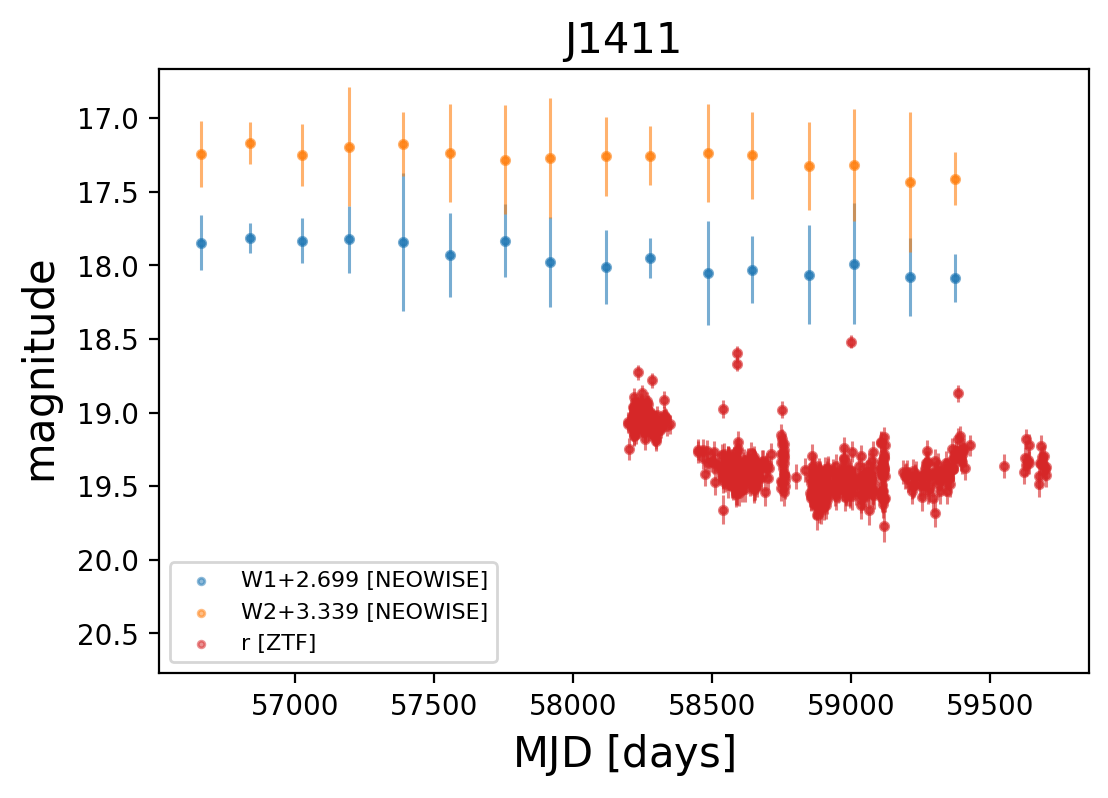

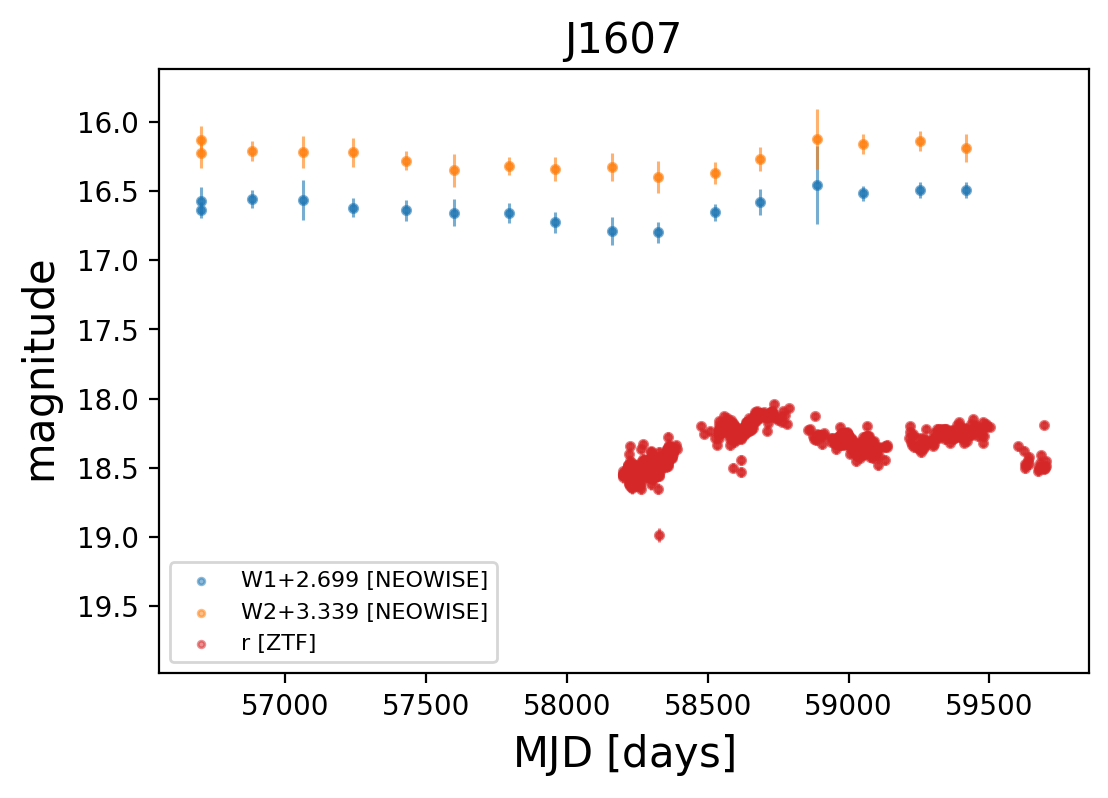

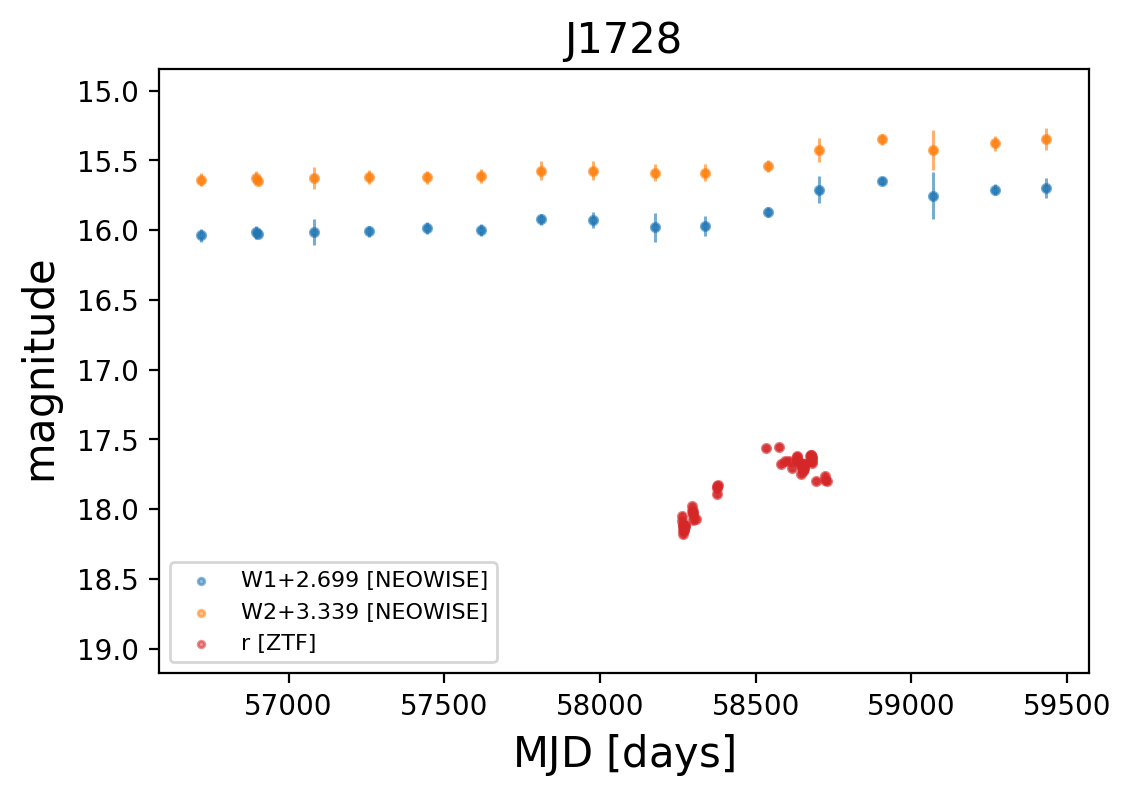

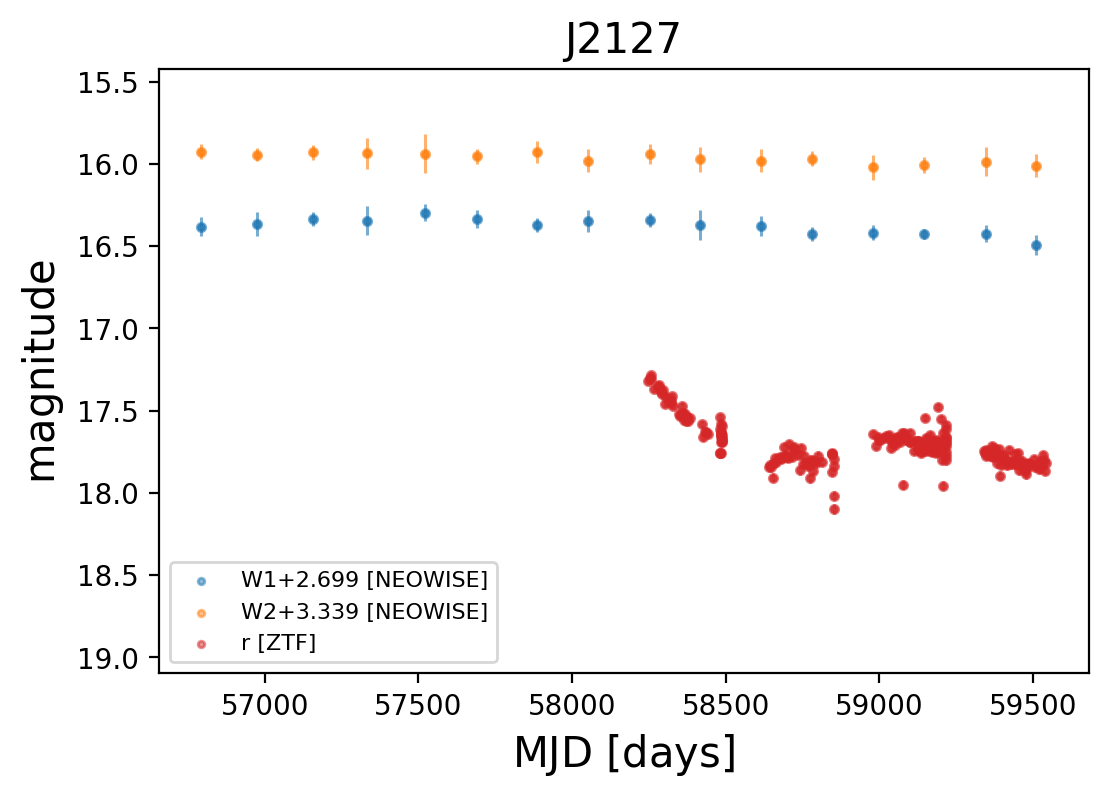

In [1556]:
for i in tnrange(len(tar_name)):
    file_path = glob.glob(dataPath+tar_name[i]+"_lcData.dat")[0]
    lcShow(file_path, tar_name[i], plot_flux=False)

## Single object 

In [11]:
## SDSS J1617+1243
tar_name = "J420"

In [12]:
## ZTF 
ztfr = fits.open("data/lc/ZTF/SDSS_J1420_ZTFr.fits")
MJD_ZTF = ztfr[1].data["MJD"]
mag_ZTF = ztfr[1].data["mag"]
mag_err_ZTF = ztfr[1].data["magerr"]

## Pan-starrs
panr = pd.read_csv("data/lc/Pan_starrs/SDSS_J1420_Panstarrs.csv")
pan_t = np.array(panr["epochMean"])
pan_r_mag = np.array(panr["rMeanApMag"])
pan_r_mag_err = np.array(panr["rMeanApMagErr"])

## PTF
ptfr = pd.read_csv("data/lc/PTF/SDSS_J1420_PTF_r.csv")
ptft = np.array(ptfr["obsmjd"])
ptfmag = np.array(ptfr["mag_autocorr"])
ptfmagerr = np.array(ptfr["magerr_auto"])

## SDSS
# SDSS J1617 
# SDSS_t = np.array([53504])
# SDSS_r_mag = np.array([18.59])
# SDSS_r_mag_err = np.array([0.01])

# SDSS J1420
SDSS_t = np.array([52758])
SDSS_r_mag = np.array([18.89])
SDSS_r_mag_err = np.array([0.01])

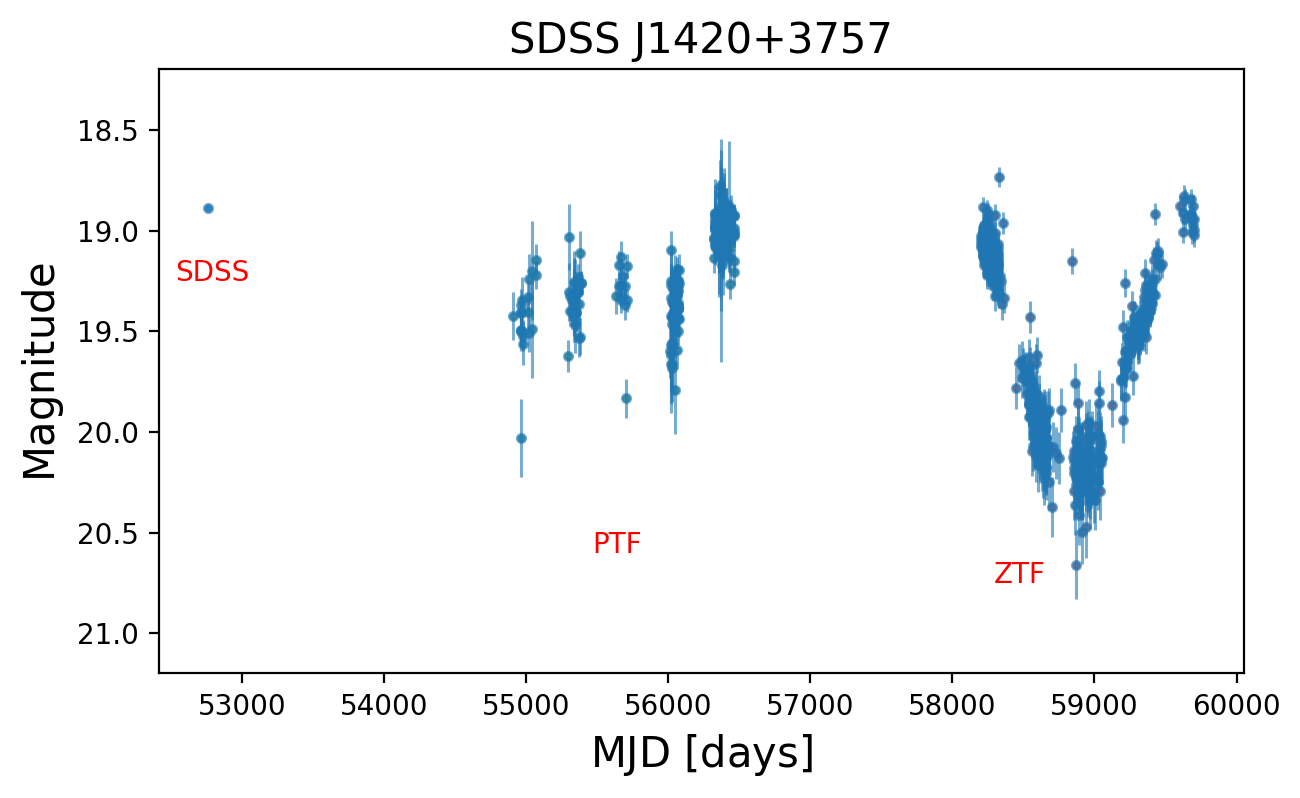

In [14]:
fig = plt.figure(figsize = (7,4), dpi = 200)
ax  = plt.subplot(111)
ax.tick_params(axis='both', which='major', labelsize=10)
ax.tick_params(axis='both', which='minor', labelsize=10)
ax.set_xlabel(r"${\rm  MJD\ [days]}$", fontsize=15)
ax.set_title("SDSS J1420+3757", fontsize=15)
ax.set_ylabel(r"${\rm Magnitude }$", fontsize=15)
ax.set_ylim(21.2, 18.2)

ax.errorbar(SDSS_t, SDSS_r_mag, yerr = SDSS_r_mag_err, linestyle = 'None', color = "C0", marker = 'o',
                    ms=3, elinewidth=1.1, alpha = 0.6)
ax.scatter(SDSS_t, SDSS_r_mag, color = 'C0', s = 4, alpha = 0.5, label = "[SDSS]")

# ax.errorbar(pan_t, pan_r_mag, yerr = pan_r_mag_err, linestyle = 'None', color = "C1", marker = 'o',
#                     ms=3, elinewidth=1.1, alpha = 0.6)
# ax.scatter(pan_t, pan_r_mag, color = 'C1', s = 4, alpha = 0.5, label = "[Pan-Starrs]")

ax.errorbar(ptft, ptfmag, yerr = ptfmagerr, linestyle = 'None', color = "C0", marker = 'o',
                    ms=3, elinewidth=1.1, alpha = 0.6)
ax.scatter(ptft, ptfmag, color = 'C2', s = 4, alpha = 0.5, label = "[PTF]")

ax.errorbar(MJD_ZTF, mag_ZTF, yerr = mag_err_ZTF, linestyle = 'None', color = "C0", marker = 'o',
                    ms=3, elinewidth=1.1, alpha = 0.6)
ax.scatter(MJD_ZTF, mag_ZTF, color = 'C3', s = 4, alpha = 0.5, label = "[ZTF]")


ax.text(0.015,0.65,'SDSS',transform=ax.transAxes,fontdict={'size': '10', 'color': 'red'})
ax.text(0.400,0.20,'PTF',transform=ax.transAxes,fontdict={'size': '10', 'color': 'red'})
ax.text(0.770,0.15,'ZTF',transform=ax.transAxes,fontdict={'size': '10', 'color': 'red'})

plt.savefig('image/'+tar_name+'_optical_lc.pdf',dpi=600,bbox_inches='tight')

# Bayesian Block

In [142]:
def bayesian_blocks(t):
    """Bayesian Blocks Implementation

    By Jake Vanderplas.  License: BSD
    Based on algorithm outlined in http://adsabs.harvard.edu/abs/2012arXiv1207.5578S

    Parameters
    ----------
    t : ndarray, length N
        data to be histogrammed

    Returns
    -------
    bins : ndarray
        array containing the (N+1) bin edges

    Notes
    -----
    This is an incomplete implementation: it may fail for some
    datasets.  Alternate fitness functions and prior forms can
    be found in the paper listed above.
    """
    # copy and sort the array
    t = np.sort(t)
    N = t.size

    # create length-(N + 1) array of cell edges
    edges = np.concatenate([t[:1],
                            0.5 * (t[1:] + t[:-1]),
                            t[-1:]])
    block_length = t[-1] - edges

    # arrays needed for the iteration
    nn_vec = np.ones(N)
    best = np.zeros(N, dtype=float)
    last = np.zeros(N, dtype=int)

    #-----------------------------------------------------------------
    # Start with first data cell; add one cell at each iteration
    #-----------------------------------------------------------------
    for K in range(N):
        # Compute the width and count of the final bin for all possible
        # locations of the K^th changepoint
        width = block_length[:K + 1] - block_length[K + 1]
        count_vec = np.cumsum(nn_vec[:K + 1][::-1])[::-1]

        # evaluate fitness function for these possibilities
        fit_vec = count_vec * (np.log(count_vec) - np.log(width))
        fit_vec -= 4  # 4 comes from the prior on the number of changepoints
        fit_vec[1:] += best[:K]

        # find the max of the fitness: this is the K^th changepoint
        i_max = np.argmax(fit_vec)
        last[K] = i_max
        best[K] = fit_vec[i_max]

    #-----------------------------------------------------------------
    # Recover changepoints by iteratively peeling off the last block
    #-----------------------------------------------------------------
    change_points =  np.zeros(N, dtype=int)
    i_cp = N
    ind = N
    while True:
        i_cp -= 1
        change_points[i_cp] = ind
        if ind == 0:
            break
        ind = last[ind - 1]
    change_points = change_points[i_cp:]

    return edges[change_points]

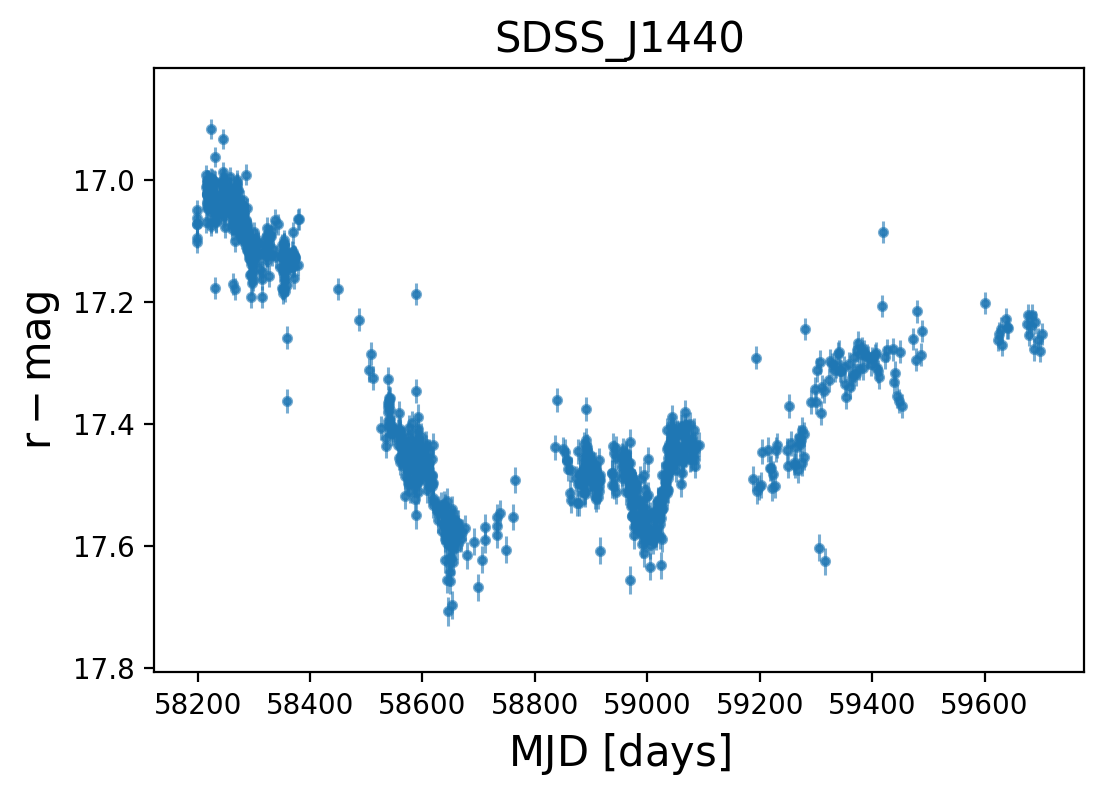

In [415]:
lc_1440 = lc_check(file_name[0], plot=True, chk_file=True)

In [418]:
t_1440 = lc_1440[1].data["MJD"]
rmag_1440 = lc_1440[1].data["mag"]
rmag_1440_err = lc_1440[1].data["magerr"]

# J1427+2930 (AT2019brs)

## Spectrum

In [15]:
sdss_data=fits.open("data/SDSS/SDSS_J142746.39+293038.2.fits")

z=sdss_data[2].data['z'][0]                # Redshift
lam=10**sdss_data[1].data['loglam']        # OBS wavelength [A]
rest_lam = lam/(1+z)
flux=sdss_data[1].data['flux']             # OBS flux [erg/s/cm^2/A]
err=1./np.sqrt(sdss_data[1].data['ivar'])  # 1 sigma error


gtc_C_data = fits.open("data/GTC-OSIRIS/Sci_spec/combined_grism/SDSS_J1427GTC_OSIRIS.fits")
wave_c = gtc_C_data[1].data["wave"]
rest_wave = wave_c/(1+z)
flux_c = gtc_C_data[1].data["flux"]
var_c = gtc_C_data[1].data["var"]

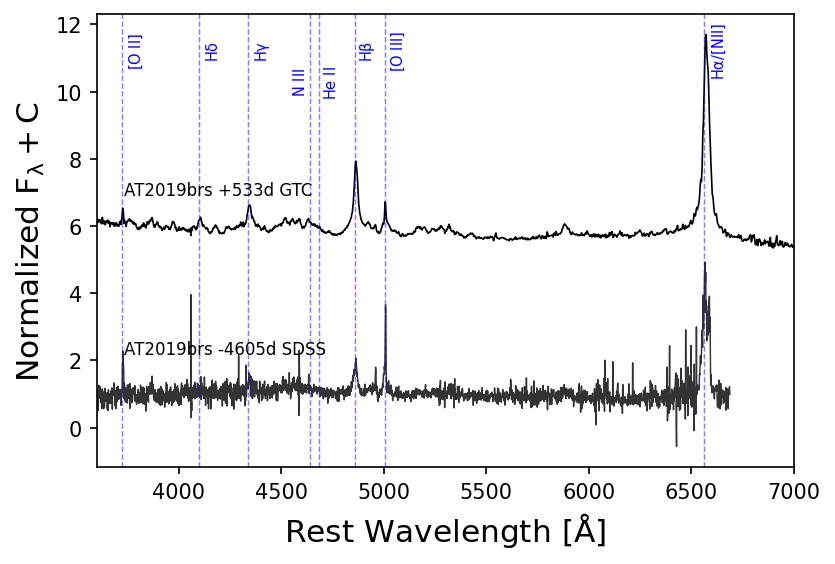

In [17]:
fig = plt.figure(figsize = (6,4), dpi = 150)
ax  = plt.subplot(111)
ax.tick_params(axis='both', which='major', labelsize=10)
ax.tick_params(axis='both', which='minor', labelsize=10)
ax.set_xlabel(r"${\rm  Rest\ Wavelength\ [\AA]}$", fontsize=15)
ax.set_ylabel(r"${\rm  Normalized\ F_{\lambda}+C }$", fontsize=15)

ax.plot(rest_lam,flux/5,c='k',lw=0.7, alpha = 0.8)
ax.plot(rest_wave,flux_c/5+5,c='k',lw=0.8)

ax.text(0.04,0.25,'AT2019brs -4605d SDSS',transform=ax.transAxes,fontdict={'size': '8', 'color': 'black'})
ax.text(0.04,0.60,'AT2019brs +533d GTC',transform=ax.transAxes,fontdict={'size': '8', 'color': 'black'})

fontdict_emline=dict(fontsize=7, color='b',family='DejaVu Sans',weight='light')
color = 'b'
line_alpha = 0.5
line_lw = 0.7
ax.axvline(x = 3726, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
ax.text(0.045 ,0.92,r'${\rm [O\ II]}$',transform=ax.transAxes,fontdict=fontdict_emline,rotation=90, va='center')

ax.axvline(x = 4101, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
ax.text(0.155,0.92,r'${\rm H\delta}$',transform=ax.transAxes,fontdict=fontdict_emline,rotation=90, va='center')

ax.axvline(x = 4340, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
ax.text(0.225,0.92,r'${\rm H\gamma}$',transform=ax.transAxes,fontdict=fontdict_emline,rotation=90, va='center')

ax.axvline(x = 4640, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
ax.text(0.28 ,0.85,r'${\rm N\ III}$',transform=ax.transAxes,fontdict=fontdict_emline,rotation=90, va='center')

ax.axvline(x = 4686, color = color,linestyle="--",alpha=line_alpha,lw=line_lw)
ax.text(0.325,0.85,r'${\rm He\ II}$',transform=ax.transAxes,fontdict=fontdict_emline,rotation=90, va='center')

ax.axvline(x = 4861, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
ax.text(0.375,0.92,r'${\rm H\beta}$',transform=ax.transAxes,fontdict=fontdict_emline,rotation=90, va='center')

# ax.axvline(x = 4959, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
ax.axvline(x = 5007, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
ax.text(0.42 ,0.92,r'${\rm [O\ III]}$',transform=ax.transAxes,fontdict=fontdict_emline,rotation=90, va='center')

ax.axvline(x = 6563, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
ax.text(0.88,0.92,r'${\rm H\alpha / [NII]}$',transform=ax.transAxes,fontdict=fontdict_emline,rotation=90, va='center')

plt.xlim(3600,7000)
plt.savefig("image/J1427_2epoch_spec.pdf",dpi=600,bbox_inches = 'tight')

## Light curve data

In [16]:
## load data optical

## ZTF

lc_df_1427 = ascii.read("data/lc/J1427_lcData.dat")

### r band
t_1427 = lc_df_1427["MJD"][lc_df_1427["band"] == 'r']
mag_1427 = lc_df_1427["mag"][lc_df_1427["band"] == 'r']
mag_1427_err = lc_df_1427["magerr"][lc_df_1427["band"] == 'r']

### g band
t_1427_g = lc_df_1427["MJD"][lc_df_1427["band"] == 'g']
gmag_1427 = lc_df_1427["mag"][lc_df_1427["band"] == 'g']
gmag_1427_err = lc_df_1427["magerr"][lc_df_1427["band"] == 'g']

### i band 
t_1427_i = lc_df_1427["MJD"][lc_df_1427["band"] == 'i']
imag_1427 = lc_df_1427["mag"][lc_df_1427["band"] == 'i']
imag_1427_err = lc_df_1427["magerr"][lc_df_1427["band"] == 'i']

In [17]:
tg_mask = (t_1427_g > 58400) & (t_1427_g < 59242)
tr_mask = (t_1427 > 58400) & (t_1427 < 59242)
ti_mask = (t_1427_i > 58400) & (t_1427_i < 59242)

g_MJD = list(np.array(t_1427_g[tg_mask]))
g_mag = list(gmag_1427[tg_mask])
g_mag_err = list(gmag_1427_err[tg_mask])
g_band_s = list(len(g_MJD)*["g"])

r_MJD = list(np.array(t_1427[tr_mask]))
r_mag = list(mag_1427[tr_mask])
r_mag_err = list(mag_1427_err[tr_mask])
r_band_s = list(len(r_MJD)*["r"])

i_MJD = list(np.array(t_1427_i[ti_mask]))
i_mag = list(imag_1427[ti_mask])
i_mag_err = list(imag_1427_err[ti_mask])
i_band_s = list(len(i_MJD)*["i"])

time_MJD = g_MJD+r_MJD+i_MJD
mag_tol = g_mag+r_mag+i_mag
mag_err_tol = g_mag_err+r_mag_err+i_mag_err
band_name = g_band_s+r_band_s+i_band_s
tele_name = list(len(time_MJD)*["ZTF"])


In [18]:
# data = Table()

# data["MJD"] = time_MJD
# data["mag"] = mag_tol
# data["magerr"] = mag_err_tol
# data["band"] = band_name
# data["telescope"] = tele_name

# ascii.write(data,"data/lc_1427_cutlc.dat",overwrite=True)

In [19]:
## SDSS

SDSS_t = np.array([53111])
SDSS_r_mag = np.array([19.151])
SDSS_r_mag_err = np.array([0.012])

In [20]:
## PTF 

# ptf_t = np.array([56782])
# ptf_r_mag = np.array([19.198])
# ptf_r_mag_err = np.array([0.0753])

data_ptf = pd.read_csv("data/lc/PTF/SDSS_J1427_PTF_r.csv")
ptf_t = np.array(data_ptf["obsmjd"])
ptf_r_mag = np.array(data_ptf["mag_autocorr"])
ptf_r_mag_err = np.array(data_ptf["magerr_auto"])

In [21]:
## Pan-Starrs

data_pan = pd.read_csv("data/lc/Pan_starrs/SDSS_J1427_Panstarrs.csv")
pan_t = np.array(data_pan["epochMean"])
pan_r_mag = np.array(data_pan["rMeanPSFMag"])
pan_r_mag_err = np.array(data_pan["rMeanPSFMagErr"])

pan_mask = np.where(pan_r_mag_err>0)
pan_t = pan_t[pan_mask]
pan_r_mag = pan_r_mag[pan_mask]
pan_r_mag_err = pan_r_mag_err[pan_mask]


In [22]:
## data WISE W1: 3.4 um, W2: 4.6 um 

data_WISE = pd.read_csv("data/lc/neoWISE/neoWISESDSSJ1427.csv")
WISE_t = np.array(data_WISE["mjd"])
W1_mag = np.array(data_WISE["w1mpro"])
W1_mag_err = np.array(data_WISE["w1sigmpro"])
W2_mag = np.array(data_WISE["w2mpro"])
W2_mag_err = np.array(data_WISE["w2sigmpro"])

In [23]:
WISE_t_new = [56671,]
WISE_tint = np.floor(WISE_t)
for i in np.arange(len(WISE_tint)-1):
    if WISE_tint[i+1] - WISE_tint[i] > 100:
        WISE_t_new.append(int(WISE_tint[i+1]))
    else:
        pass
    
mask_list = list(np.unique((WISE_tint - 56670)//100))
del mask_list[7]
mask_list = np.array(mask_list)

WISE_tint_norm = np.array((WISE_tint - 56670)//100)

W1_mag_new = []
W1_mag_err_new = []
W2_mag_new = []
W2_mag_err_new = []
for idx in np.arange(len(mask_list)):
    ii = mask_list[idx]
    W1_l = []
    W2_l = []
    for j in np.arange(len(WISE_tint_norm)):

        jj = WISE_tint_norm[j]
        if jj == ii:
            W1_l.append(W1_mag[j])
            W2_l.append(W2_mag[j])
        else:
            W1_l.append(np.nan)
            W2_l.append(np.nan)
    W1_mag_new.append(np.nanmedian(np.array(W1_l)))
    W1_mag_err_new.append(np.nanstd(np.array(W1_l)))
    W2_mag_new.append(np.nanmedian(np.array(W2_l)))
    W2_mag_err_new.append(np.nanstd(np.array(W2_l)))

In [24]:
WISE_t_new = np.array(WISE_t_new)
W1_mag_new = np.array(W1_mag_new)
W1_mag_err_new = np.array(W1_mag_err_new)
W2_mag_new = np.array(W2_mag_new)
W2_mag_err_new = np.array(W2_mag_err_new)

## lc (mag)

In [25]:
plt.rcParams["xtick.direction"] = "in"
plt.rcParams["ytick.direction"] = "in"
plt.rcParams["xtick.top"] = True
plt.rcParams["ytick.right"] = True
plt.rcParams["xtick.minor.visible"] = True
plt.rcParams["ytick.minor.visible"] = True
plt.rcParams["xtick.labelsize"] = 14
plt.rcParams["ytick.labelsize"] = 14

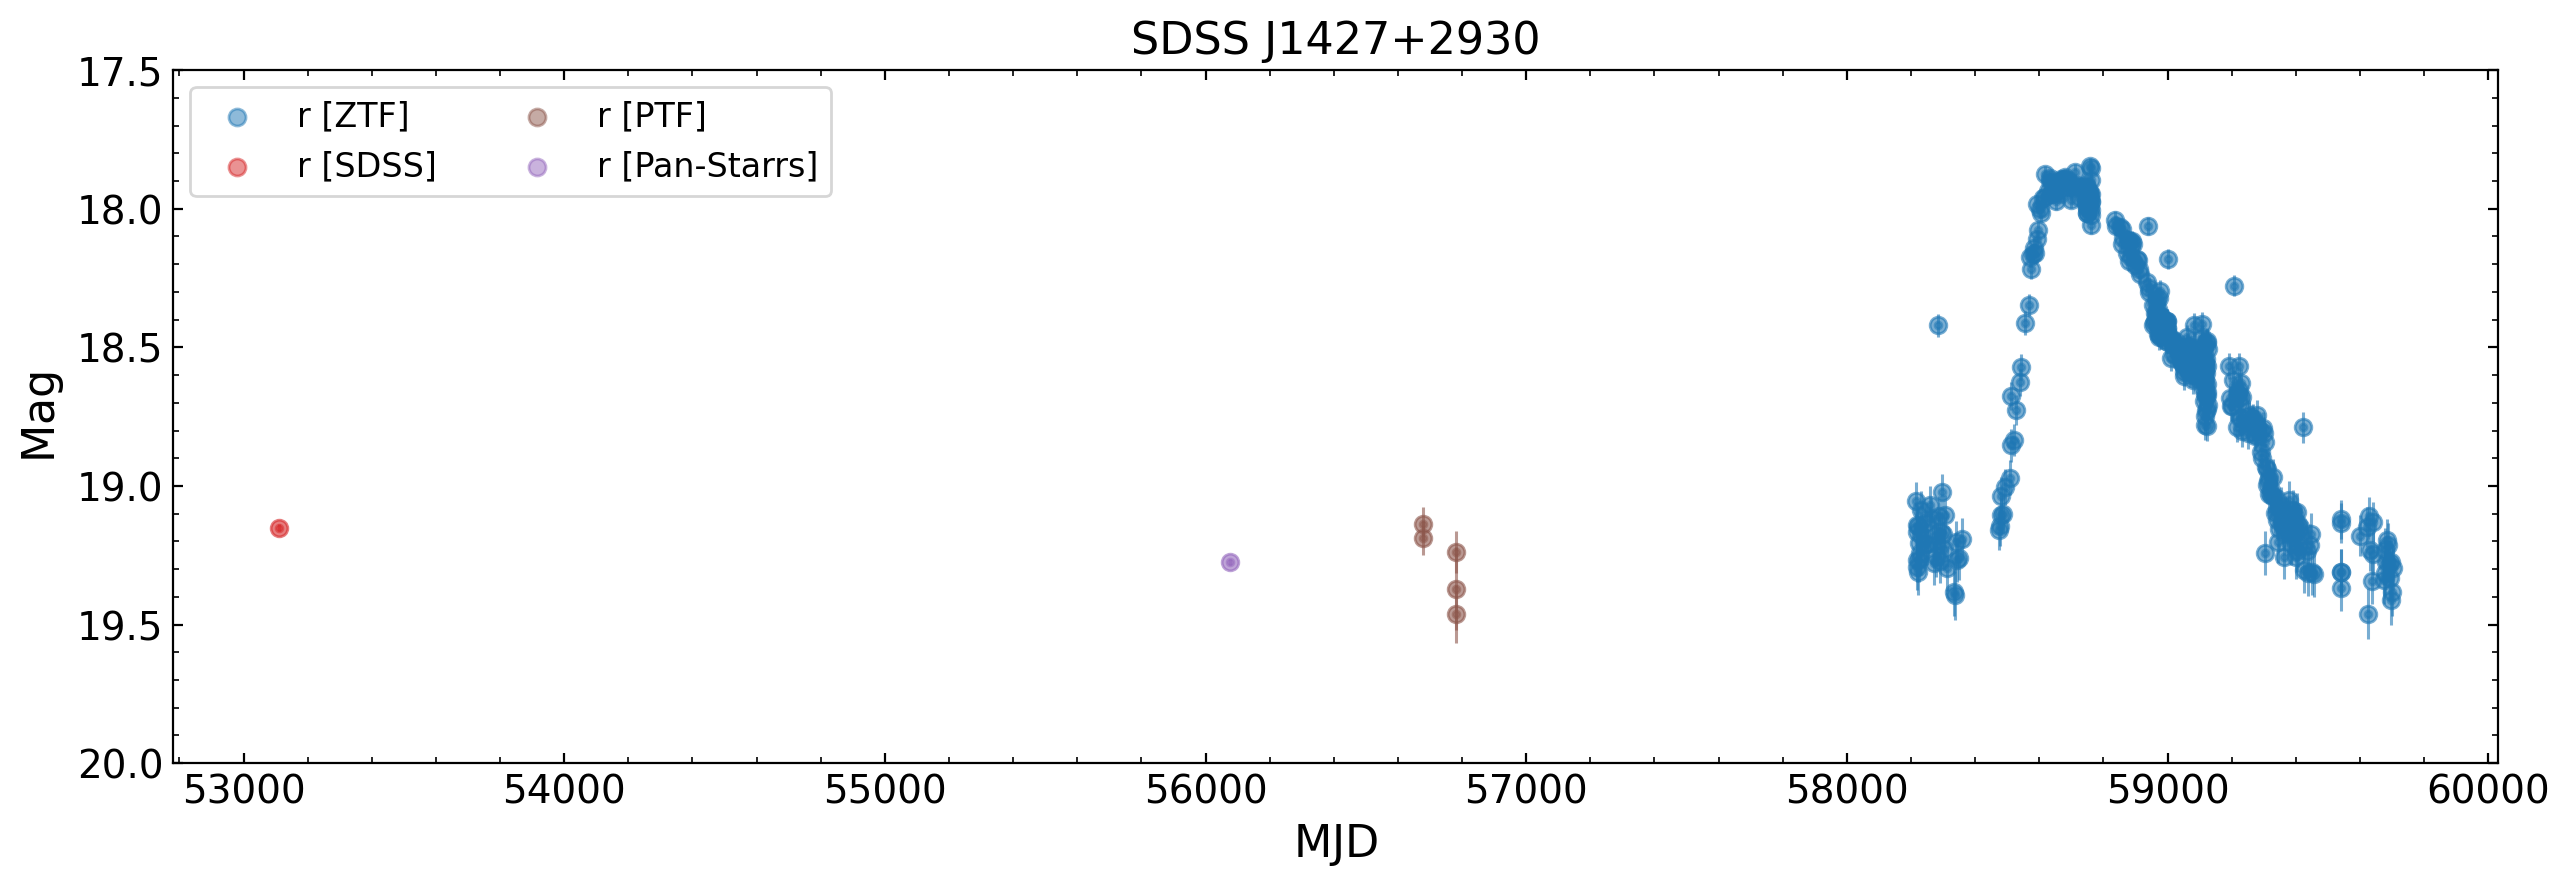

In [27]:
fig = plt.figure(figsize = (15,4.5), dpi = 200)

ax  = plt.subplot(111)
ax.set_xlabel(r"${\rm MJD}$", fontsize=16)
ax.set_ylabel(r"${\rm Mag }$", fontsize=16)
ax.set_title('SDSS J1427+2930', fontsize=16)


ax.set_ylim(20, 17.5)
# ax.set_xlim(-1000,1000)

plot_triband = 0
plot_triins  = 1

t_start = 58522+120
ax.errorbar(t_1427, mag_1427, yerr = mag_1427_err, 
            linestyle = 'None', color = "C0", marker = 'o', ms=6, elinewidth=1.1, alpha = 0.6)
ax.scatter(t_1427, mag_1427, color = 'C0', s = 6, alpha = 0.5, label = "r [ZTF]" )

# ax.axvline(x = 0, color = 'k',linestyle="--", alpha=line_alpha,lw=line_lw)
# ax.text(0.235 ,0.92,r'${\rm peak}$',transform=ax.transAxes,fontdict=fontdict_emline,rotation=0, va='center')

# ax.axvline(x = 59055, color = 'k',linestyle="--", alpha=0.7, label = "GTC")
# ax.text(0.80,0.1,'GTC',transform=ax.transAxes,fontdict={'size': '10', 'color': 'black'})
# ax.axvline(x = 53917, color = 'k',linestyle="--", alpha=0.7)
# ax.text(0.18,0.1,'SDSS',transform=ax.transAxes,fontdict={'size': '10', 'color': 'black'})

if plot_triband:
    ax.errorbar(WISE_t_new-t_start, W1_mag_new+2.683, yerr = W1_mag_err_new, 
                linestyle = 'None', color = "C3", marker = 'o', ms=3, elinewidth=1.1, alpha = 0.6)
    ax.scatter(WISE_t_new-t_start, W1_mag_new+2.683, color = 'C3', s = 4, alpha = 0.5, label = "W1 [WISE]" )
    
    ax.errorbar(WISE_t_new-t_start, W2_mag_new+3.319, yerr = W2_mag_err_new, 
                linestyle = 'None', color = "C4", marker = 'o', ms=3, elinewidth=1.1, alpha = 0.6)
    ax.scatter(WISE_t_new-t_start, W2_mag_new+3.319, color = 'C4', s = 4, alpha = 0.5, label = "W2 [WISE]" )
    
    ax.errorbar(t_1427_g-t_start, gmag_1427, yerr = gmag_1427_err, 
                linestyle = 'None', color = "C1", marker = 'o', ms=3, elinewidth=1.1, alpha = 0.6)
    ax.scatter(t_1427_g-t_start, gmag_1427, color = 'C1', s = 4, alpha = 0.5, label = "g [ZTF]" )

    ax.errorbar(t_1427_i-t_start, imag_1427, yerr = imag_1427_err, 
                linestyle = 'None', color = "C2", marker = 'o', ms=3, elinewidth=1.1, alpha = 0.6)
    ax.scatter(t_1427_i-t_start, imag_1427, color = 'C2', s = 4, alpha = 0.5, label = "i [ZTF]" )

if plot_triins:
    
    ax.errorbar(SDSS_t, SDSS_r_mag, yerr = SDSS_r_mag_err, 
                linestyle = 'None', color = "C3", marker = 'o', ms=6, elinewidth=1.1, alpha = 0.6)
    ax.scatter(SDSS_t, SDSS_r_mag, color = 'C3', s = 6, alpha = 0.5, label = "r [SDSS]" )
    
    ax.errorbar(ptf_t, ptf_r_mag, yerr = ptf_r_mag_err, 
                linestyle = 'None', color = "C5", marker = 'o', ms=6, elinewidth=1.1, alpha = 0.6)
    ax.scatter(ptf_t, ptf_r_mag, color = 'C5', s = 6, alpha = 0.5, label = "r [PTF]" )

    ax.errorbar(pan_t, pan_r_mag, yerr = pan_r_mag_err, 
                linestyle = 'None', color = "C4", marker = 'o', ms=6, elinewidth=1.1, alpha = 0.6)
    ax.scatter(pan_t, pan_r_mag, color = 'C4', s = 6, alpha = 0.5, label = "r [Pan-Starrs]" )


plt.legend(loc = 'upper left', fontsize = 12, markerscale = 2.5, ncol = 2)

# plt.savefig('image/J1427_lc_multiins.pdf',dpi=600,bbox_inches='tight')

In [29]:
np.mean(W2_mag_err_new)

0.11976479335119504

## lc (L)

In [30]:
dist = cosmo.luminosity_distance(0.37362438).cgs.value

g_nuL, g_nuL_err = mag2L(gmag_1427, gmag_1427_err, dist=dist, ins='ZTF', band='g', logscale = True)
r_nuL, r_nuL_err = mag2L(mag_1427, mag_1427_err, dist=dist, ins='ZTF', band='r', logscale = True)
i_nuL, i_nuL_err = mag2L(imag_1427, imag_1427_err, dist=dist, ins='ZTF', band='i', logscale = True)
W1_nuL, W1_nuL_err = mag2L(W1_mag_new, W1_mag_err_new, dist=dist, ins='WISE', band='W1', logscale = True)
W2_nuL, W2_nuL_err = mag2L(W2_mag_new, W2_mag_err_new, dist=dist, ins='WISE', band='W2', logscale = True)

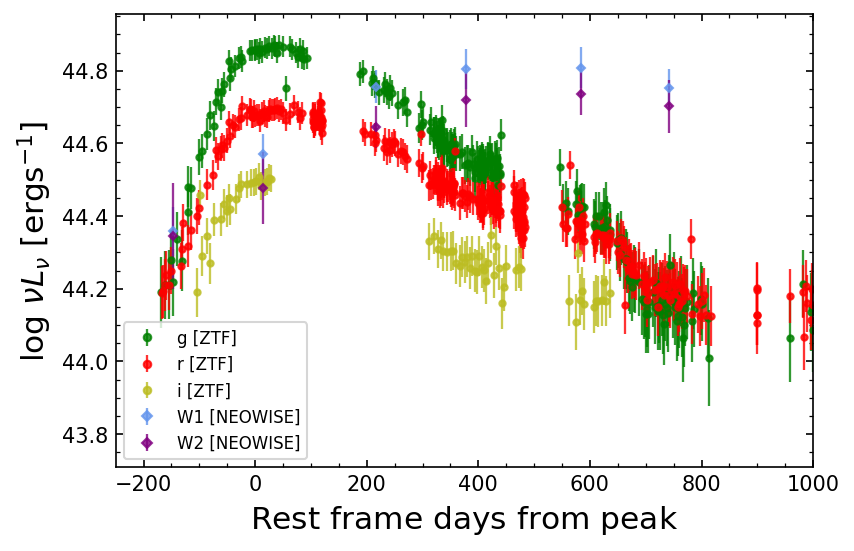

In [31]:
fig = plt.figure(figsize = (6,4), dpi = 150)
ax  = plt.subplot(111)
ax.tick_params(axis='both', which='major', labelsize=10)
ax.tick_params(axis='both', which='minor', labelsize=10)
ax.set_xlabel(r"${\rm Rest\ frame\ days\ from\ peak}$", fontsize=15)
ax.set_ylabel(r"${{\rm log}\ \nu L_{\nu}\ [\rm ergs^{-1}] }$", fontsize=15)
# ax.set_ylim(20.5, 12)
ax.set_xlim(-250,1000)

ebar_alpha = 0.8

ax.errorbar(t_1427_g-t_start, g_nuL, yerr = g_nuL_err, 
            linestyle = 'None', color = "g", marker = 'o', ms=3, elinewidth=1.1, alpha = ebar_alpha, label = "g [ZTF]" )
# ax.scatter(t_1427_g-t_start, g_nuL, color = 'g', s = 4, alpha = 0.5, label = "g [ZTF]" )
ax.errorbar(t_1427-t_start, r_nuL, yerr = r_nuL_err, 
            linestyle = 'None', color = "r", marker = 'o', ms=3, elinewidth=1.1, alpha = ebar_alpha, label = "r [ZTF]")
# ax.scatter(t_1427-t_start, r_nuL, color = 'r', s = 4, alpha = 0.5, label = "r [ZTF]" )
ax.errorbar(t_1427_i-t_start, i_nuL, yerr = i_nuL_err, 
            linestyle = 'None', color = "C8", marker = 'o', ms=3, elinewidth=1.1, alpha = ebar_alpha, label = "i [ZTF]")
# ax.scatter(t_1427_i-t_start, i_nuL, color = 'C8', s = 4, alpha = 0.5, label = "i [ZTF]" )

ax.errorbar(WISE_t_new-t_start, W1_nuL, yerr = W1_nuL_err, 
            linestyle = 'None', color = "cornflowerblue", marker = 'D', ms=3, elinewidth=1.1, alpha = ebar_alpha, label = "W1 [NEOWISE]" )
# ax.scatter(WISE_t_new-t_start, W1_nuL, color = 'cornflowerblue', s = 4, alpha = 1, marker = 'D', label = "W1 [WISE]" )

ax.errorbar(WISE_t_new-t_start, W2_nuL, yerr = W2_nuL_err, 
            linestyle = 'None', color = "purple", marker = 'D', ms=3, elinewidth=1.1, alpha = ebar_alpha, label = "W2 [NEOWISE]")
# ax.scatter(WISE_t_new-t_start, W2_nuL, color = 'purple', s = 4, alpha = 1, marker = 'D', label = "W2 [WISE]" )

# ax.axhline(y = L_edd-1, color = 'k',linestyle="--", alpha=line_alpha,lw=line_lw)
# ax.text(0.375 ,0.92,r'${\rm peak}$',transform=ax.transAxes,fontdict=fontdict_emline,rotation=0, va='center')

plt.legend(fontsize = 8.0,markerscale = 1.2)

# plt.savefig("image/AT2019brs_lc.pdf",dpi=600,bbox_inches = 'tight')0

## Eddington ratio

In [32]:
L_bol = r_nuL + np.log10(9)
L_edd = 1.26*10**(38)*10**(7.9)
L_Ledd = 10**L_bol/L_edd

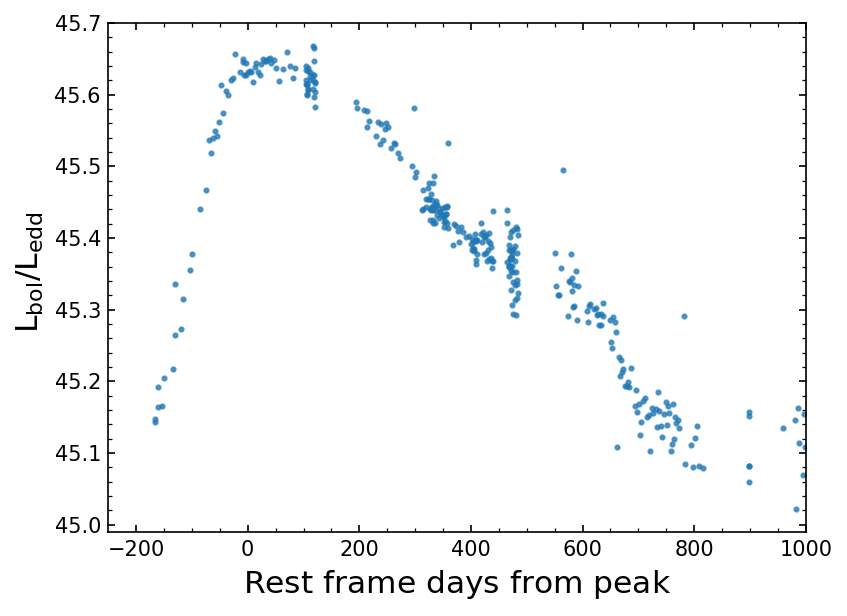

In [33]:
fig = plt.figure(figsize = (6,4.5), dpi = 150)
ax  = plt.subplot(111)
ax.tick_params(axis='both', which='major', labelsize=10)
ax.tick_params(axis='both', which='minor', labelsize=10)
ax.set_xlabel(r"${\rm Rest\ frame\ days\ from\ peak}$", fontsize=15)
ax.set_ylabel(r"${\rm\ L_{bol}/L_{edd}  }$", fontsize=15)
# ax.set_ylim(20.5, 12)
ax.set_xlim(-250,1000)

ax.scatter(t_1427-t_start, L_bol, color = 'C0', s = 4, alpha = 0.7 )

## color

In [34]:
def rebin_lc(mjd, mag, binsize, ):
    t_list_bin = np.unique(mjd//binsize)
    t_norm = np.array(mjd//binsize)
    
    mag_new = []
    mag_err_new = []
    for idx in np.arange(len(t_list_bin)):
        ii = t_list_bin[idx]
        mag_list = []
        for j in np.arange(len(t_norm)):
            jj = t_norm[j]
            if jj == ii:
                mag_list.append(mag[j])
            else:
                mag_list.append(np.nan)
        mag_new.append(np.nanmedian(np.array(mag_list)))
        mag_err_new.append(np.nanstd(np.array(mag_list)))

    mag_new = np.array(mag_new)
    mag_err_new = np.array(mag_err_new)
    mjd_new = t_list_bin*binsize
    
    return mjd_new, mag_new, mag_err_new

In [35]:
## rebin lc 
# t_1427 mag_1427 mag_1427_err r-band test
r_mjd_bin, r_mag_bin, r_mag_err_bin = rebin_lc(t_1427, mag_1427,10)
g_mjd_bin, g_mag_bin, g_mag_err_bin = rebin_lc(t_1427_g, gmag_1427,10)

t_gr = np.intersect1d(g_mjd_bin,r_mjd_bin)

t_gr_mask = (t_gr>58400)&(t_gr<60000)

g_gr_mask = np.isin(g_mjd_bin, t_gr[t_gr_mask], invert=False)
r_gr_mask = np.isin(r_mjd_bin, t_gr[t_gr_mask], invert=False)
g_mag_gr = g_mag_bin[g_gr_mask]
g_mag_err_gr = g_mag_err_bin[g_gr_mask]
r_mag_gr = r_mag_bin[r_gr_mask]
r_mag_err_gr = r_mag_err_bin[r_gr_mask]

g_r = g_mag_gr-r_mag_gr
g_r_err = np.sqrt(g_mag_err_gr**2 + r_mag_err_gr**2)

(0.5, -1e-05)

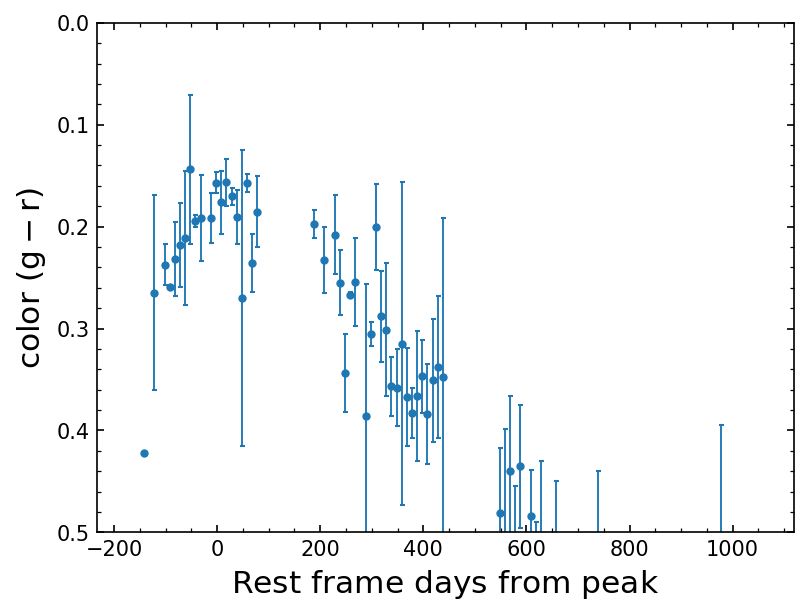

In [36]:
fig = plt.figure(figsize = (6,4.5), dpi = 150)
ax  = plt.subplot(111)
ax.tick_params(axis='both', which='major', labelsize=10)
ax.tick_params(axis='both', which='minor', labelsize=10)
ax.set_xlabel(r"${\rm  Rest\ frame\ days\ from\ peak}$", fontsize=15)
ax.set_ylabel(r"${\rm   color\ (g-r) }$", fontsize=15)
# ax.set_title('SDSSJ1427', fontsize=15)

# plt.scatter(t_gr[t_gr_mask]-58650,g_mag_gr,linestyle="None",color='g',s = 6, alpha = 0.8)
# plt.scatter(t_gr[t_gr_mask]-58650,r_mag_gr,linestyle="None",color='r',s = 6, alpha = 0.8)
# plt.ylim(20,17)

# plt.scatter(t_gr[t_gr_mask]-t_start,g_r,linestyle="None",color='b',s = 6, alpha = 0.8)
plt.errorbar(t_gr[t_gr_mask]-t_start,g_r,yerr = g_r_err, linestyle="None", 
             color = "C0", marker = 'o', ms=3, elinewidth=0.9, alpha = 1, capsize=1.2)

# ax.axvline(x = 0, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)
# ax.text(0.375 ,0.92,r'${\rm peak}$',transform=ax.transAxes,fontdict=fontdict_emline,rotation=0, va='center')

plt.ylim(0.5,-1e-5)
# plt.xlim(58645-58650,58900-58650)
# plt.savefig("image/AT2019brs_gr_color.pdf",dpi=600,bbox_inches = 'tight')

## lc + color

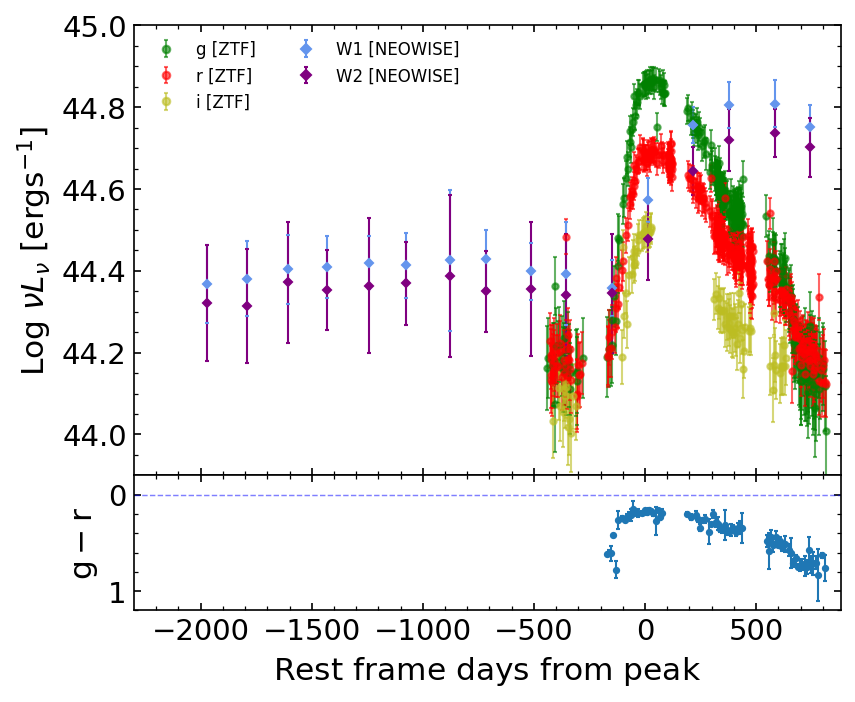

In [38]:
fig = plt.figure(figsize= (6,6),dpi=150)

plt.rcParams["xtick.direction"] = "in"
plt.rcParams["ytick.direction"] = "in"
plt.rcParams["xtick.top"] = True
plt.rcParams["ytick.right"] = True
plt.rcParams["xtick.minor.visible"] = True
plt.rcParams["ytick.minor.visible"] = True

ax_lc = plt.axes([.143, .45, .785, .50])
ax_lc.set_xticklabels([])
ax_color = plt.axes([.143,.30,.785,.15])

##########
alpha_Opt = 0.6
alpha_IR = 1
ms = 3
elw = 1 
csize = 1

Lumino = 1 
magnit = 0 
##########


ax_color.set_ylabel(r"$\rm g-r $", fontsize=15)
ax_color.set_xlabel(r"$\rm Rest\ frame\ days\ from\ peak $", fontsize=15)


ax_lc.set_xlim(-2300,880)
ax_color.set_ylim(1.2,-0.2)
ax_color.set_xlim(-2300,880)

##  luminosity 

if Lumino:
    ax_lc.errorbar(t_1427_g-t_start, g_nuL, yerr = g_nuL_err, 
                   linestyle = 'None', color = "g", marker = 'o',
                   ms=ms, elinewidth=elw, alpha = alpha_Opt, capsize=csize, label = "g [ZTF]" )

    ax_lc.errorbar(t_1427-t_start, r_nuL, yerr = r_nuL_err, 
                linestyle = 'None', color = "r", marker = 'o', 
                   ms=ms, elinewidth=elw, alpha = alpha_Opt, capsize=csize,label = "r [ZTF]")

    ax_lc.errorbar(t_1427_i-t_start, i_nuL, yerr = i_nuL_err, 
                linestyle = 'None', color = "C8", marker = 'o', 
                   ms=ms, elinewidth=elw, alpha = alpha_Opt, capsize=csize, label = "i [ZTF]")

    ax_lc.errorbar(WISE_t_new-t_start, W1_nuL, yerr = W1_nuL_err, 
                linestyle = 'None', color = "cornflowerblue", marker = 'D', 
                   ms=ms, elinewidth=elw, alpha = alpha_IR,  capsize=csize, label = "W1 [NEOWISE]" )

    ax_lc.errorbar(WISE_t_new-t_start, W2_nuL, yerr = W2_nuL_err, 
                linestyle = 'None', color = "purple", marker = 'D', 
                   ms=ms, elinewidth=elw, alpha = alpha_IR,  capsize=csize, label = "W2 [NEOWISE]")
    
    ax_lc.set_ylabel(r"${{\rm Log}\ \nu L_{\nu}\ [\rm ergs^{-1}] }$", fontsize=15)
    ax_lc.set_ylim(43.9,45)

##  magnitude 

if magnit:
    
    ax_lc.errorbar(t_1427_g-t_start, gmag_1427 - 0.9, yerr = gmag_1427_err, 
                   linestyle = 'None', color = "g", marker = 'o',
                   ms=ms, elinewidth=elw, alpha = alpha_Opt, capsize=csize, label = "g [ZTF]" )

    ax_lc.errorbar(t_1427-t_start, mag_1427, yerr = mag_1427_err, 
                linestyle = 'None', color = "r", marker = 'o', 
                   ms=ms, elinewidth=elw, alpha = alpha_Opt, capsize=csize,label = "r [ZTF]")

    ax_lc.errorbar(t_1427_i-t_start, imag_1427 + 0.9, yerr = imag_1427_err, 
                linestyle = 'None', color = "C8", marker = 'o', 
                   ms=ms, elinewidth=elw, alpha = alpha_Opt, capsize=csize, label = "i [ZTF]")

    ax_lc.errorbar(WISE_t_new-t_start, W1_mag_new +2.699, yerr = W1_mag_err_new, 
                linestyle = 'None', color = "cornflowerblue", marker = 'D', 
                   ms=ms, elinewidth=elw, alpha = alpha_IR,  capsize=csize, label = "W1 [NEOWISE]" )

    ax_lc.errorbar(WISE_t_new-t_start, W2_mag_new + 3.339, yerr = W2_mag_err_new, 
                linestyle = 'None', color = "purple", marker = 'D', 
                   ms=ms, elinewidth=elw, alpha = alpha_IR,  capsize=csize, label = "W2 [NEOWISE]")
    
    ax_lc.set_ylim(20, 15)
    ax_lc.set_ylabel(r"${\rm Magnitude}$", fontsize=15)
    
ax_lc.legend(fontsize = 8.0,markerscale = 1.2, ncol=2, framealpha = 0.)
    

## color panel
ax_color.errorbar(t_gr[t_gr_mask]-t_start,g_r,yerr = g_r_err, 
                  linestyle="None", color = "C0", marker = 'o', 
                  ms=ms-0.5, elinewidth=elw, alpha = 1, capsize=csize)

ax_color.axhline(y = 0, color = color,linestyle="--", alpha=line_alpha,lw=line_lw)


plt.savefig('image/J1427_lc_color.pdf',dpi=600,bbox_inches='tight')

In [227]:
r_nuL[83]-r_nuL[91]

0.02816925048828267

81.14047450000362

39.24156249999942

## lc fitting

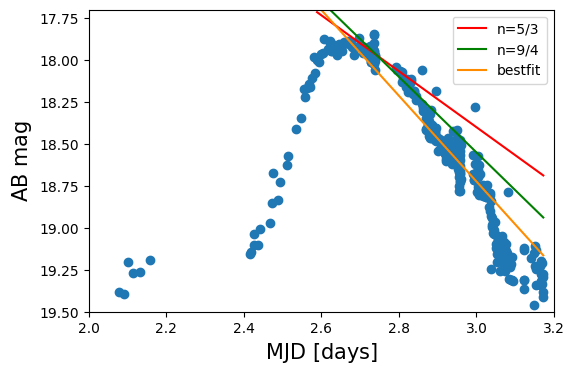

In [839]:
fig = plt.figure(figsize = (6,4), dpi = 100)
ax  = plt.subplot(111)
ax.set_xlabel(r"${\rm  MJD\ [days]}$", fontsize=15)
ax.set_ylabel(r"${\rm AB\ mag }$", fontsize=15)
logt = np.log10(t_1427 - t_1427[0])
plt.scatter(logt, mag_1427)
plt.plot(date, (5/3)*date+13.4, 'r', label='n=5/3')
plt.plot(date, (9/4)*date+11.8, 'g', label='n=9/4')
plt.plot(date, func(date, *p), 'darkorange',label = "bestfit")
plt.ylim(19.5, 17.7)
plt.xlim(2.0,3.2)
plt.legend()

In [837]:
from scipy.optimize import curve_fit
def func(x, *p):
    return p[0]*x + p[1]

t_mask = (t_1427 > 58600)
date = logt[t_mask]
mag_down = mag_1427[t_mask]
p0 = np.array([18, 1.6])
bounds = ([0,0],[30,np.inf])
p, perr = curve_fit(func, date, mag_down, p0=p0,bounds=bounds,
                                      sigma=mag_1427_err[t_mask], absolute_sigma=True,
                                      maxfev=100000)

In [838]:
p

array([ 2.55402954, 11.06132091])

# J1420+3757

In [408]:
## ZTF 
fp_1420 = 'data/lc/lc_SDSS_J1420.fits'
lc_J1420 = lc_check(fp_1420, plot=False, chk_file=True)
t_1420_r = lc_J1420[1].data["MJD"]
rmag_1420 = lc_J1420[1].data["mag"]
rmag_1420_err = lc_J1420[1].data["magerr"]

## SDSS
SDSS_t_1420 = np.array([52758])
SDSS_r_mag_1420 = np.array([18.891])
SDSS_r_mag_err_1420 = np.array([0.010])

## Pan-Starrs
data_pan_1420 = pd.read_csv("data/lc/SDSS_J1420_Pan_starrs.csv")
pan_t_1420 = np.array(data_pan_1420["epochMean"])
pan_r_mag_1420 = np.array(data_pan_1420["rMeanPSFMag"])
pan_r_mag_err_1420 = np.array(data_pan_1420["rMeanPSFMagErr"])

pan_mask_1420 = np.where(pan_r_mag_err_1420>0)
pan_t_1420 = pan_t_1420[pan_mask_1420]
pan_r_mag_1420 = pan_r_mag_1420[pan_mask_1420]
pan_r_mag_err_1420 = pan_r_mag_err_1420[pan_mask_1420]

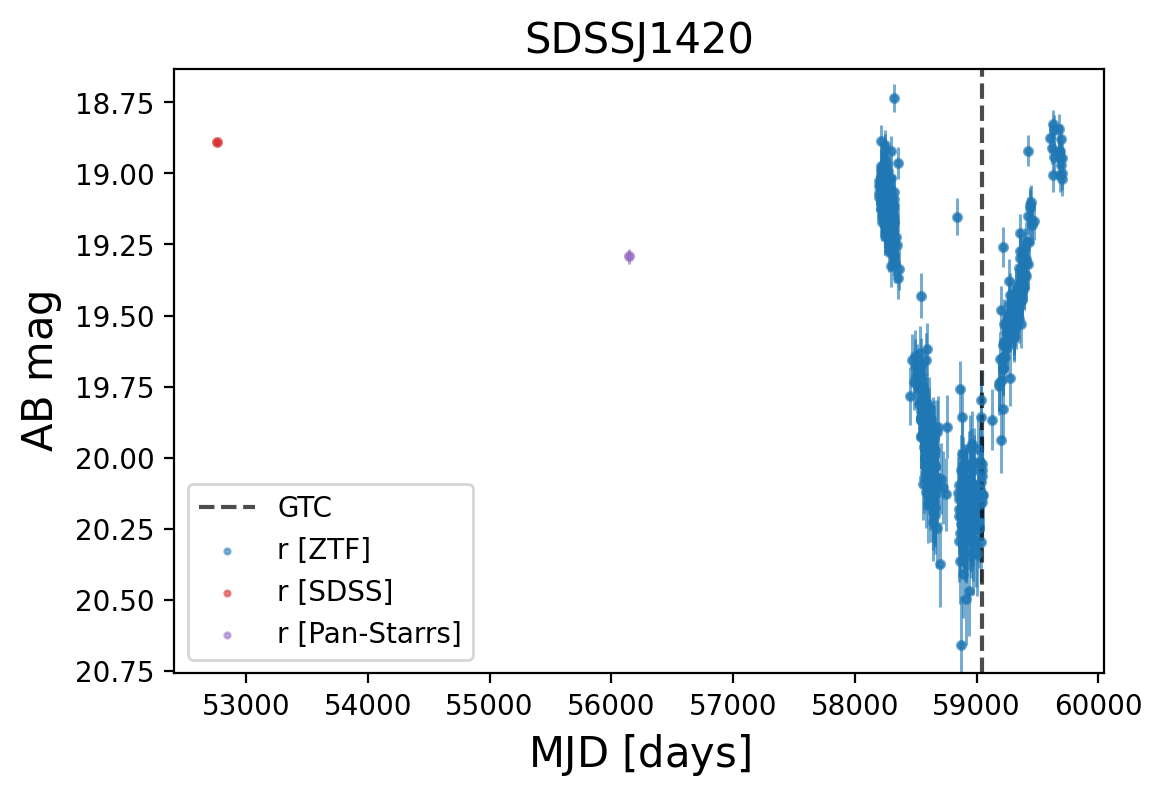

In [476]:
fig = plt.figure(figsize = (6,4), dpi = 200)
ax  = plt.subplot(111)
ax.tick_params(axis='both', which='major', labelsize=10)
ax.tick_params(axis='both', which='minor', labelsize=10)
ax.set_xlabel(r"${\rm  MJD\ [days]}$", fontsize=15)
ax.set_ylabel(r"${\rm AB\ mag }$", fontsize=15)
ax.set_title('SDSSJ1420', fontsize=15)

ax.set_ylim(rmag_1420.max()+0.1, rmag_1420.min()-0.1)
# ax.set_xlim(58400, 60000)

plot_triband = 0
plot_triins  = 1
ax.errorbar(t_1420_r, rmag_1420, yerr = rmag_1420_err, 
            linestyle = 'None', color = "C0", marker = 'o', ms=3, elinewidth=1.1, alpha = 0.6)
ax.scatter(t_1420_r, rmag_1420, color = 'C0', s = 4, alpha = 0.5, label = "r [ZTF]" )

ax.plot()
ax.axvline(x = 59045, color = 'k',linestyle="--", alpha=0.7, label = "GTC")
# ax.text(0.80,0.1,'GTC',transform=ax.transAxes,fontdict={'size': '10', 'color': 'black'})
# ax.axvline(x = 53917, color = 'k',linestyle="--", alpha=0.7)
# ax.text(0.18,0.1,'SDSS',transform=ax.transAxes,fontdict={'size': '10', 'color': 'black'})

if plot_triband:
    
    ax.errorbar(t_1427_g, gmag_1427, yerr = gmag_1427_err, 
                linestyle = 'None', color = "C1", marker = 'o', ms=3, elinewidth=1.1, alpha = 0.6)
    ax.scatter(t_1427_g, gmag_1427, color = 'C1', s = 4, alpha = 0.5, label = "g [ZTF]" )

    ax.errorbar(t_1427_i, imag_1427, yerr = imag_1427_err, 
                linestyle = 'None', color = "C2", marker = 'o', ms=3, elinewidth=1.1, alpha = 0.6)
    ax.scatter(t_1427_i, imag_1427, color = 'C2', s = 4, alpha = 0.5, label = "i [ZTF]" )

if plot_triins:
    
    ax.errorbar(SDSS_t_1420, SDSS_r_mag_1420, yerr = SDSS_r_mag_err_1420, 
                linestyle = 'None', color = "C3", marker = 'o', ms=3, elinewidth=1.1, alpha = 0.6)
    ax.scatter(SDSS_t_1420, SDSS_r_mag_1420, color = 'C3', s = 4, alpha = 0.5, label = "r [SDSS]" )

    ax.errorbar(pan_t_1420, pan_r_mag_1420, yerr = pan_r_mag_err_1420, 
                linestyle = 'None', color = "C4", marker = 'o', ms=3, elinewidth=1.1, alpha = 0.6)
    ax.scatter(pan_t_1420, pan_r_mag_1420, color = 'C4', s = 4, alpha = 0.5, label = "r [Pan-Starrs]" )


plt.legend(loc = 'lower left')

In [460]:
def sin_model(x, *p):
    
    Amp = p[0]
    w   = p[1]
    T   = p[2]
    C   = p[3]
    return Amp*np.sin(w*x*np.pi/180+T)+C

In [473]:
p0 = np.array([2, 0.3, 0.4, 19.4])
bounds = ([0, 0, 0, 0],[300, np.inf, np.inf, np.inf])
fit_t = t_1420_r - t_1420_r[0]
fit_mag = rmag_1420
fit_magerr = rmag_1420_err
p, perr = curve_fit(sin_model, fit_t, fit_mag, p0=p0,bounds=bounds,
                                      sigma=fit_magerr, absolute_sigma=True,maxfev=100000)
p

array([1.11126495e+00, 1.30742765e-01, 4.41457144e-17, 1.89559397e+01])

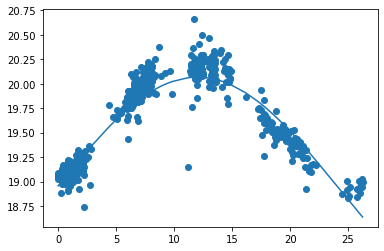

In [474]:
plt.plot(fit_t*np.pi/180, sin_model(fit_t, *p))
plt.scatter(fit_t*np.pi/180,fit_mag)

# A